In [3]:
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import pandas as pd
gdf= gpd.read_file("/home/s0shar47/scratch/OUTPUTS_Paper1/gdf_conus/gdf_conus.shp")
locations= pd.read_csv("/home/s0shar47/scratch/salil/DPL/dPL_Hydro_SNTEMP/config/gauge_loc.csv")

# Convert gauge locations to a GeoDataFrame
locations_gdf = gpd.GeoDataFrame(
    locations,
    geometry=gpd.points_from_xy(locations["LONG"], locations["LAT"]),
    crs="EPSG:4326"
)

# Make sure county polygons use the same CRS
gdf = gdf.to_crs(locations_gdf.crs)

# Spatial join
locations_with_county = gpd.sjoin(
    locations_gdf,
    gdf[["NAME", "STATE_NAME", "geometry"]],
    how="left",
    predicate="within"
).drop(columns="index_right")

# Rename columns
locations_with_county = locations_with_county.rename(
    columns={
        "NAME": "COUNTY_NAME",
        "STATE_NAME": "STATE_NAME"
    }
)

## If you don't need the geometry column afterwards
# locations = pd.DataFrame(locations_with_county.drop(columns="geometry"))

# locations

locations_with_county

,HUC_02,GAGE_ID,GAGE_NAME,LAT,LONG,DRAINAGE AREA (KM^2),geometry,COUNTY_NAME,STATE_NAME
0,1,1013500,"Fish River near Fort Kent, Maine",47.23739,-68.58264,2252.70,POINT (-68.58264 47.23739),Aroostook,Maine
1,1,1022500,"Narraguagus River at Cherryfield, M...",44.60797,-67.93524,573.60,POINT (-67.93524 44.60797),Washington,Maine
2,1,1030500,"Mattawamkeag River near Mattawamkeag, M...",45.50097,-68.30596,3676.17,POINT (-68.30596 45.50097),Penobscot,Maine
3,1,1031500,"Piscataquis River near Dover-Foxcroft, M...",45.17501,-69.31470,769.05,POINT (-69.3147 45.17501),Piscataquis,Maine
4,1,1047000,"Carrabassett River near North Anson, M...",44.86920,-69.95510,909.10,POINT (-69.9551 44.8692),Somerset,Maine
...,...,...,...,...,...,...,...,...,...
666,17,14309500,WEST FORK COW CREEK NEAR GLENDALE...,42.80400,-123.61091,224.92,POINT (-123.61091 42.804),Douglas,Oregon
667,17,14316700,STEAMBOAT CREEK NEAR GLIDE...,43.34984,-122.72894,587.90,POINT (-122.72894 43.34984),Douglas,Oregon
668,17,14325000,SOUTH FORK COQUILLE RIVER AT POWERS...,42.89150,-124.07065,443.07,POINT (-124.07065 42.8915),Coos,Oregon
669,17,14362250,"STAR GULCH NEAR RUCH,...",42.15401,-123.07532,41.42,POINT (-123.07532 42.15401),Jackson,Oregon


Number of basins: 677


<Axes: >

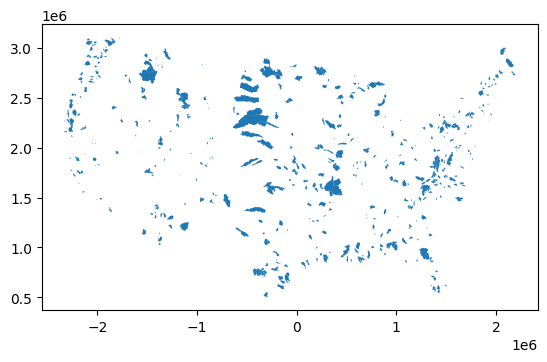

In [24]:
import geopandas as gpd

path = "/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/shapefiles/merge/basinset_gf_nhru.shp"

gdf = gpd.read_file(path)

# Remove records without a GAGEID
gdf = gdf[gdf["GAGEID"].notna()].copy()

# Dissolve all HRUs belonging to the same gauged basin
basins = gdf.dissolve(by="GAGEID", as_index=False)

print("Number of basins:", len(basins))

# basins.to_file(
#     "/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/shapefiles/CAMELS_671_basins.shp"
# )
basins.plot()


In [26]:
import numpy as np
import geopandas as gpd

forcing = np.load(
    "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
)

gage_ids = forcing[:, 0, 14].astype(int)

gdf = basins
gdf["GAGEID"] = gdf["GAGEID"].astype(int)

gdf_671 = gdf[gdf["GAGEID"].isin(gage_ids)].copy()

print("Forcing IDs:", len(gage_ids))
print("Shapefile basins:", len(gdf))
print("Matched basins:", len(gdf_671))
print("Unique matched GAGEIDs:", gdf_671["GAGEID"].nunique())


Forcing IDs: 671
Shapefile basins: 677
Matched basins: 671
Unique matched GAGEIDs: 671


In [ ]:
# ============================================================
# COUNTY-BASED SPATIAL AVERAGE OF RC_eff TIFFs FOR EACH GAUGE
#
# Years: 2000 - 2013
#
# For each gauge:
#   1. Find the county containing the gauge
#   2. Calculate the spatial mean of RC_eff_YEAR.tif
#      over that county
#   3. Assign that county mean to the gauge
#
# Output:
#   - One row per gauge
#   - One column per year
#   - Long-format CSV
#   - Wide-format CSV
#   - Gauge/county GeoPackage
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio

from rasterstats import zonal_stats


# ============================================================
# 1. PATHS
# ============================================================

COUNTY_SHP = (
    "/home/s0shar47/scratch/OUTPUTS_Paper1/"
    "gdf_conus/gdf_conus.shp"
)

basin= ("/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/shapefiles/CAMELS_671_basins.shp")

GAUGE_CSV = (
    "/home/s0shar47/scratch/salil/DPL/"
    "dPL_Hydro_SNTEMP/config/gauge_loc.csv"
)

RASTER_BASE = (
    "/home/s0shar47/scratch/Recharge_reitz"
)

OUTPUT_DIR = (
    "/home/s0shar47/scratch/Recharge_reitz/"
    "gauge_county_average"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ============================================================
# 2. YEARS
# ============================================================

YEARS = list(range(2000, 2014))


# ============================================================
# 3. READ COUNTY SHAPEFILE
# ============================================================

print("\n" + "=" * 80)
print("STEP 1: READING COUNTY SHAPEFILE")
print("=" * 80)

counties = gpd.read_file(
    COUNTY_SHP
)

print(
    f"Number of county polygons: {len(counties)}"
)

print(
    f"County CRS: {counties.crs}"
)

print(
    "County columns:"
)

print(
    counties.columns.tolist()
)


# ------------------------------------------------------------
# Keep required columns
# ------------------------------------------------------------

counties = counties[
    [
        "NAME",
        "STATE_NAME",
        "geometry"
    ]
].copy()


# ------------------------------------------------------------
# Fix invalid geometries
# ------------------------------------------------------------

print("\nChecking county geometries...")

invalid_before = (
    ~counties.geometry.is_valid
).sum()

print(
    f"Invalid geometries before repair: "
    f"{invalid_before}"
)

if invalid_before > 0:

    counties["geometry"] = (
        counties.geometry.make_valid()
    )

invalid_after = (
    ~counties.geometry.is_valid
).sum()

print(
    f"Invalid geometries after repair: "
    f"{invalid_after}"
)


# ============================================================
# 4. CREATE UNIQUE COUNTY ID
# ============================================================

# IMPORTANT:
# Do NOT use county name + state as the unique key.
#
# The county shapefile may contain multiple polygons with
# identical NAME/STATE_NAME combinations.
#
# COUNTY_ID uniquely identifies the actual polygon.

counties["COUNTY_ID"] = np.arange(
    len(counties)
)

print(
    f"\nUnique county polygons: "
    f"{counties['COUNTY_ID'].nunique()}"
)


# ============================================================
# 5. READ GAUGE LOCATIONS
# ============================================================

print("\n" + "=" * 80)
print("STEP 2: READING GAUGE LOCATIONS")
print("=" * 80)

locations = pd.read_csv(
    GAUGE_CSV
)

print(
    f"Number of gauges: {len(locations)}"
)

print(
    "Gauge columns:"
)

print(
    locations.columns.tolist()
)


# ============================================================
# 6. CREATE GAUGE GEODATAFRAME
# ============================================================

locations_gdf = gpd.GeoDataFrame(
    locations.copy(),
    geometry=gpd.points_from_xy(
        locations["LONG"],
        locations["LAT"]
    ),
    crs="EPSG:4326"
)

print(
    f"\nGauge CRS: {locations_gdf.crs}"
)


# ============================================================
# 7. SPATIAL JOIN GAUGES TO COUNTIES
# ============================================================

print("\n" + "=" * 80)
print("STEP 3: ASSIGNING EACH GAUGE TO A COUNTY")
print("=" * 80)


# Reproject county polygons to gauge CRS
counties_wgs84 = counties.to_crs(
    "EPSG:4326"
)


# ------------------------------------------------------------
# Spatial join
# ------------------------------------------------------------

locations_with_county = gpd.sjoin(
    locations_gdf,

    counties_wgs84[
        [
            "COUNTY_ID",
            "NAME",
            "STATE_NAME",
            "geometry"
        ]
    ],

    how="left",

    predicate="within"
).drop(
    columns=["index_right"]
)


# ------------------------------------------------------------
# Rename county name
# ------------------------------------------------------------

locations_with_county = (
    locations_with_county.rename(
        columns={
            "NAME": "COUNTY_NAME"
        }
    )
)


# ============================================================
# 8. CHECK NUMBER OF GAUGES AFTER SPATIAL JOIN
# ============================================================

print(
    f"\nNumber of rows after spatial join: "
    f"{len(locations_with_county)}"
)

print(
    f"Original number of gauges: "
    f"{len(locations_gdf)}"
)


if len(locations_with_county) != len(locations_gdf):

    print(
        "\nWARNING:"
    )

    print(
        "The spatial join changed the number of rows."
    )

    print(
        "This can happen when a gauge falls on a county "
        "boundary or a polygon overlaps another polygon."
    )


# ============================================================
# 9. CHECK GAUGES WITHOUT COUNTY
# ============================================================

missing_county = (
    locations_with_county[
        locations_with_county["COUNTY_ID"].isna()
    ]
)

print(
    f"\nGauges without a county: "
    f"{len(missing_county)}"
)


if len(missing_county) > 0:

    print(
        "\nGauges without county:"
    )

    cols = [
        c
        for c in [
            "STAID",
            "ID",
            "LAT",
            "LONG"
        ]
        if c in missing_county.columns
    ]

    print(
        missing_county[cols].to_string(
            index=False
        )
    )


# ============================================================
# 10. HANDLE POSSIBLE DUPLICATE GAUGES
# ============================================================

# Create an internal unique gauge ID.
#
# This is important because we want exactly one row per gauge.

locations_with_county = (
    locations_with_county.reset_index(
        drop=True
    )
)

locations_with_county["_GAUGE_ID"] = np.arange(
    len(locations_with_county)
)


# ============================================================
# 11. SAVE GAUGE-COUNTY ASSIGNMENT
# ============================================================

gauge_county_csv = os.path.join(
    OUTPUT_DIR,
    "gauge_county_assignment.csv"
)

locations_with_county.drop(
    columns=["geometry"]
).to_csv(
    gauge_county_csv,
    index=False
)

print(
    f"\nGauge-county assignment saved:"
)

print(
    gauge_county_csv
)


# ============================================================
# 12. CREATE RESULTS DATAFRAME
# ============================================================

# This dataframe will ALWAYS contain one row per gauge.

results = locations_with_county.drop(
    columns=["geometry"]
).copy()


print(
    f"\nInitial results rows: "
    f"{len(results)}"
)


# ============================================================
# 13. PROCESS EACH YEAR
# ============================================================

print("\n" + "=" * 80)
print("STEP 4: PROCESSING ANNUAL TIFF FILES")
print("=" * 80)


for year in YEARS:

    print("\n")
    print("-" * 80)

    print(
        f"YEAR {year}"
    )

    print("-" * 80)


    # ========================================================
    # TIFF PATH
    # ========================================================

    tif_path = (
        f"{RASTER_BASE}/"
        f"EffRecharge_{year}/"
        f"{year}/"
        f"RC_eff_{year}.tif"
    )

    print(
        f"TIFF:\n{tif_path}"
    )


    # ========================================================
    # CHECK TIFF EXISTS
    # ========================================================

    if not os.path.isfile(
        tif_path
    ):

        print(
            f"WARNING: TIFF not found for {year}"
        )

        results[
            f"mean_{year}"
        ] = np.nan

        continue


    # ========================================================
    # OPEN TIFF
    # ========================================================

    with rasterio.open(
        tif_path
    ) as src:

        print(
            f"Raster CRS: {src.crs}"
        )

        print(
            f"Raster dimensions: "
            f"{src.width} x {src.height}"
        )

        print(
            f"Raster resolution: "
            f"{src.res}"
        )

        print(
            f"Raster NoData: "
            f"{src.nodata}"
        )


        raster_crs = src.crs

        raster_nodata = src.nodata


    # ========================================================
    # REPROJECT COUNTY POLYGONS TO RASTER CRS
    # ========================================================

    counties_raster = (
        counties.to_crs(
            raster_crs
        )
    )


    # ========================================================
    # CALCULATE COUNTY ZONAL MEANS
    # ========================================================

    print(
        "Calculating spatial mean for each county..."
    )


    stats = zonal_stats(

        counties_raster.geometry,

        tif_path,

        stats=[
            "mean"
        ],

        nodata=raster_nodata,

        all_touched=False
    )


    # ========================================================
    # EXTRACT MEAN VALUES
    # ========================================================

    county_means = np.array(
        [
            (
                stat["mean"]
                if stat["mean"] is not None
                else np.nan
            )

            for stat in stats
        ],

        dtype=float
    )


    # ========================================================
    # ADD COUNTY MEAN TO COUNTY DATAFRAME
    # ========================================================

    counties_raster[
        f"mean_{year}"
    ] = county_means


    # ========================================================
    # CHECK COUNTY RESULTS
    # ========================================================

    valid_counties = np.isfinite(
        county_means
    ).sum()

    missing_counties = np.isnan(
        county_means
    ).sum()


    print(
        f"Counties with valid mean: "
        f"{valid_counties}"
    )

    print(
        f"Counties without valid mean: "
        f"{missing_counties}"
    )


    # ========================================================
    # CREATE COUNTY LOOKUP
    # ========================================================

    #
    # IMPORTANT:
    # Only COUNTY_ID is used for merging.
    #

    county_lookup = counties_raster[
        [
            "COUNTY_ID",
            f"mean_{year}"
        ]
    ].copy()


    # ========================================================
    # CHECK COUNTY_ID UNIQUENESS
    # ========================================================

    if county_lookup[
        "COUNTY_ID"
    ].duplicated().any():

        raise ValueError(
            "COUNTY_ID is not unique. "
            "The county shapefile contains duplicate IDs."
        )


    # ========================================================
    # MERGE COUNTY VALUE TO GAUGES
    # ========================================================

    results = results.merge(

        county_lookup,

        on="COUNTY_ID",

        how="left",

        validate="many_to_one"
    )


    # ========================================================
    # VERIFY NUMBER OF GAUGES DID NOT CHANGE
    # ========================================================

    print(
        f"Rows after {year} merge: "
        f"{len(results)}"
    )


    if len(results) != len(
        locations_with_county
    ):

        raise ValueError(
            f"Number of gauge rows changed "
            f"after processing {year}."
        )


    # ========================================================
    # CHECK GAUGE VALUES
    # ========================================================

    valid_gauges = (
        results[
            f"mean_{year}"
        ].notna().sum()
    )

    missing_gauges = (
        results[
            f"mean_{year}"
        ].isna().sum()
    )


    print(
        f"Gauges with valid {year} value: "
        f"{valid_gauges}"
    )

    print(
        f"Gauges with missing {year} value: "
        f"{missing_gauges}"
    )


    print(
        f"Finished {year}"
    )


# ============================================================
# 14. FINAL CHECK
# ============================================================

print("\n" + "=" * 80)
print("STEP 5: FINAL DATA CHECK")
print("=" * 80)


print(
    f"Number of gauges: "
    f"{len(results)}"
)


print(
    f"Number of columns: "
    f"{len(results.columns)}"
)


# ------------------------------------------------------------
# Check annual columns
# ------------------------------------------------------------

year_columns = [
    f"mean_{year}"
    for year in YEARS
]


print(
    "\nAnnual columns:"
)

for year in YEARS:

    column = f"mean_{year}"

    if column in results.columns:

        n_valid = (
            results[column]
            .notna()
            .sum()
        )

        n_missing = (
            results[column]
            .isna()
            .sum()
        )

        print(
            f"{year}: "
            f"{n_valid} valid, "
            f"{n_missing} missing"
        )


# ============================================================
# 15. SAVE WIDE FORMAT
# ============================================================

print("\n" + "=" * 80)
print("STEP 6: SAVING WIDE FORMAT")
print("=" * 80)


wide_csv = os.path.join(
    OUTPUT_DIR,
    "RC_eff_county_mean_2000_2013_wide.csv"
)


results.to_csv(
    wide_csv,
    index=False
)


print(
    f"Saved:\n{wide_csv}"
)


# ============================================================
# 16. CREATE LONG FORMAT
# ============================================================

print("\n" + "=" * 80)
print("STEP 7: CREATING LONG FORMAT")
print("=" * 80)


# ------------------------------------------------------------
# Metadata columns
# ------------------------------------------------------------

id_columns = [
    c
    for c in results.columns
    if c not in year_columns
]


# ------------------------------------------------------------
# Melt
# ------------------------------------------------------------

results_long = results.melt(

    id_vars=id_columns,

    value_vars=year_columns,

    var_name="YEAR",

    value_name="RC_eff_county_mean"
)


# ------------------------------------------------------------
# Convert year to integer
# ------------------------------------------------------------

results_long["YEAR"] = (
    results_long["YEAR"]
    .str.replace(
        "mean_",
        "",
        regex=False
    )
    .astype(int)
)


# ============================================================
# 17. SAVE LONG FORMAT
# ============================================================

long_csv = os.path.join(
    OUTPUT_DIR,
    "RC_eff_county_mean_2000_2013_long.csv"
)


results_long.to_csv(
    long_csv,
    index=False
)


print(
    f"Saved:\n{long_csv}"
)


# ============================================================
# 18. SAVE GEOPACKAGE
# ============================================================

print("\n" + "=" * 80)
print("STEP 8: SAVING GEOPACKAGE")
print("=" * 80)


# ------------------------------------------------------------
# Start with gauge geometries
# ------------------------------------------------------------

results_gdf = locations_with_county.copy()


# ------------------------------------------------------------
# Add annual values
#
# We use _GAUGE_ID so that there is no accidental
# many-to-many merge.
# ------------------------------------------------------------

for year in YEARS:

    column = f"mean_{year}"

    if column not in results.columns:

        continue


    values = results[
        [
            "_GAUGE_ID",
            column
        ]
    ].copy()


    results_gdf = results_gdf.merge(

        values,

        on="_GAUGE_ID",

        how="left",

        validate="one_to_one"
    )


# ------------------------------------------------------------
# Save GeoPackage
# ------------------------------------------------------------

gpkg_path = os.path.join(
    OUTPUT_DIR,
    "RC_eff_county_mean_2000_2013.gpkg"
)


results_gdf.to_file(

    gpkg_path,

    layer="gauge_county_recharge",

    driver="GPKG"
)


print(
    f"Saved:\n{gpkg_path}"
)


# ============================================================
# 19. REMOVE INTERNAL GAUGE ID FROM CSV OUTPUT
# ============================================================

# The internal _GAUGE_ID is useful for the GeoPackage,
# but you may not want it in the final CSV.

results_clean = results.drop(
    columns=[
        "_GAUGE_ID"
    ],
    errors="ignore"
)


results_long_clean = results_long.drop(
    columns=[
        "_GAUGE_ID"
    ],
    errors="ignore"
)


# Re-save cleaned CSVs

results_clean.to_csv(
    wide_csv,
    index=False
)

results_long_clean.to_csv(
    long_csv,
    index=False
)


# ============================================================
# 20. DISPLAY SAMPLE
# ============================================================

print("\n" + "=" * 80)
print("SAMPLE RESULTS")
print("=" * 80)


print(
    results_clean.head()
    .to_string(index=False)
)


# ============================================================
# 21. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("PROCESSING COMPLETE")
print("=" * 80)


print(
    f"Number of gauges: "
    f"{len(results_clean)}"
)

print(
    f"Years: "
    f"{YEARS[0]} - {YEARS[-1]}"
)


print("\nOutput files:")

print(
    f"1. Gauge-county assignment:\n"
    f"   {gauge_county_csv}"
)

print(
    f"\n2. Wide CSV:\n"
    f"   {wide_csv}"
)

print(
    f"\n3. Long CSV:\n"
    f"   {long_csv}"
)

print(
    f"\n4. GeoPackage:\n"
    f"   {gpkg_path}"
)


print("\n" + "=" * 80)
print("DONE")
print("=" * 80)



STEP 1: READING COUNTY SHAPEFILE
Number of county polygons: 3108
County CRS: EPSG:4326
County columns:
['STATEFP', 'COUNTYFP', 'COUNTYNS', 'GEOID', 'NAME', 'NAMELSAD', 'LSAD', 'CLASSFP', 'MTFCC', 'CSAFP', 'CBSAFP', 'METDIVFP', 'FUNCSTAT', 'ALAND', 'AWATER', 'INTPTLAT', 'INTPTLON', 'STATE_NAME', 'geometry']

Checking county geometries...
Invalid geometries before repair: 0
Invalid geometries after repair: 0

Unique county polygons: 3108

STEP 2: READING GAUGE LOCATIONS
Number of gauges: 671
Gauge columns:
['HUC_02', 'GAGE_ID', 'GAGE_NAME', 'LAT', 'LONG', 'DRAINAGE AREA (KM^2)']

Gauge CRS: EPSG:4326

STEP 3: ASSIGNING EACH GAUGE TO A COUNTY

Number of rows after spatial join: 671
Original number of gauges: 671

Gauges without a county: 0

Gauge-county assignment saved:
/home/s0shar47/scratch/Recharge_reitz/gauge_county_average/gauge_county_assignment.csv

Initial results rows: 671

STEP 4: PROCESSING ANNUAL TIFF FILES


------------------------------------------------------------------

In [ ]:
## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

method= 'Furey'
methods= ['USGS', 'Furey', 'Eckhardt']
## Select the test
test= 'PUB'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'PRMS', 'HBV_capillary']

if model=='HBV':
    dyn= 'parBETA_parBETAET_'

if model=='marrmot_PRMS':
    dyn= 'alpha_cgw_scx_tt_'

if model=='HBV_capillary':
    dyn= 'parBETA_parBETAET_parK0_parUZL_'

if test== 'PUB':
    n=11
if test== 'PUR':
    n=8

    
import numpy as np
import os




models= ['HBV', 'HBV_capillary', 'marrmot_PRMS']
for k in range(len(models)):
    model= models[k]

    if model=='HBV':
        dyn= 'parBETA_parBETAET_'

    if model=='marrmot_PRMS':
        dyn= 'alpha_cgw_scx_tt_'

    if model=='HBV_capillary':
        dyn= 'parBETA_parBETAET_parK0_parUZL_'

# ============================================================
    for i in range(1, n):


        if test== 'PUB':
            folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUB/{method}_{objectives[1]}/{i}/"
                
            sfolder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUB/OUTPUTS_PUB_{objectives[0]}/{i}/"

            forcing = np.load(f"/scratch/data/{test}_DATA/test/{i}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy")
 

        if test== 'PUR':
            folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/{method}_{objectives[1]}/Region_{i}/"
            sfolder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_{objectives[0]}/Region_{i}/"


            forcing = np.load(
                f"/scratch/data/{test}_DATA/test/Region_{i}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
            )

        sim_old = np.load(
            os.path.join(sfolder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1980_2014/recharge.npy")
        )

        sim_new = np.load(
            os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1980_2014/recharge.npy")
        )

        sim_old = np.squeeze(sim_old)
        sim_new = np.squeeze(sim_new)

        # --------------------------------------------------------
        # Loop over basins
        # --------------------------------------------------------
        # for k in range(sim_new.shape[1]):
        for k in range(1):

            gauge = forcing[k,0,14]
            old = sim_old[:, k]
            new = sim_new[:, k]


            plt.figure(figsize=(18,6))
            plt.plot(new)
            plt.show()


Number of dates: 12418

Loading TIFF recharge...
TIFF shape: (671, 23)
Gauge ID column: GAGE_ID
Number of TIFF gauges: 671


MODEL: HBV
DYNAMIC: parBETA_parBETAET_


--------------------------------------------------------------------------------
REGION: 1
--------------------------------------------------------------------------------

Raw recharge shapes:
sim_old: (12418, 52)
sim_new: (12418, 52)
OLD is (time, basins). Transposing...
NEW is (time, basins). Transposing...

Final recharge shapes:
sim_old: (52, 12418)
sim_new: (52, 12418)

Number of basins: 52
Number of daily values: 12418

Calculating annual means...
      2000: 366 days
      2001: 365 days
      2002: 365 days
      2003: 365 days
      2004: 366 days
      2005: 365 days
      2006: 365 days
      2007: 365 days
      2008: 366 days
      2009: 365 days
      2010: 365 days
      2011: 365 days
      2012: 366 days
      2013: 365 days
      2000: 366 days
      2001: 365 days
      2002: 365 days
      2003: 365 da

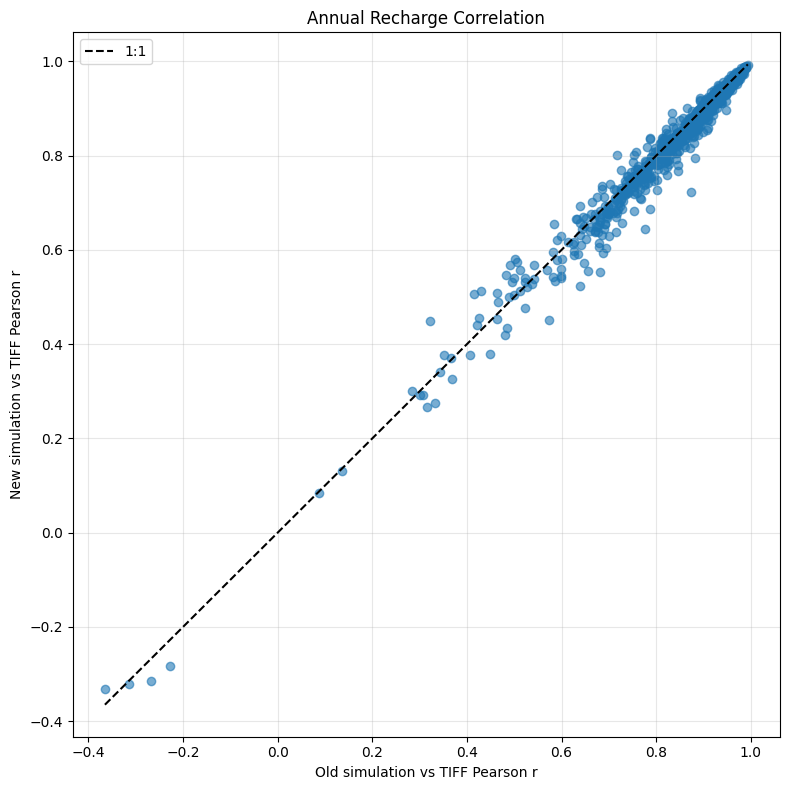

In [20]:
# ============================================================
# SIMULATED RECHARGE vs TIFF COUNTY RECHARGE
#
# recharge.npy actual shape:
#
#       (12418, 52)
#
#       12418 = TIME
#       52    = BASINS
#
# We transpose to:
#
#       (52, 12418)
#
#       52    = BASINS
#       12418 = TIME
#
# Time:
#       1981-01-01 to 2014-12-31
#
# Comparison:
#       Annual mean recharge
#       2000-2013
#
# ============================================================


# ============================================================
# IMPORTS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import pearsonr


# ============================================================
# SETTINGS
# ============================================================

objectives = [
    "Single",
    "Multi"
]

method = "Furey"

test = "PUB"

models = [
    "HBV",
    "HBV_capillary",
    "marrmot_PRMS"
]


# ============================================================
# YEARS
# ============================================================

START_YEAR = 2000
END_YEAR = 2013

YEARS = np.arange(
    START_YEAR,
    END_YEAR + 1
)


# ============================================================
# DAILY DATES
# ============================================================

dates = pd.date_range(
    start="1981-01-01",
    end="2014-12-31",
    freq="D"
)


print(
    "Number of dates:",
    len(dates)
)


# ============================================================
# TIFF DATA
# ============================================================

TIFF_CSV = (
    "/home/s0shar47/scratch/"
    "Recharge_reitz/gauge_county_average/"
    "RC_eff_county_mean_2000_2013_wide.csv"
)


print("\nLoading TIFF recharge...")

tiff_data = pd.read_csv(
    TIFF_CSV
)


print(
    "TIFF shape:",
    tiff_data.shape
)


# ============================================================
# GAUGE ID COLUMN
# ============================================================

if "GAGE_ID" in tiff_data.columns:

    GAUGE_ID_COLUMN = "GAGE_ID"

elif "ID" in tiff_data.columns:

    GAUGE_ID_COLUMN = "ID"

else:

    raise ValueError(
        "Could not find STAID or ID in TIFF data."
    )


print(
    "Gauge ID column:",
    GAUGE_ID_COLUMN
)


# ============================================================
# GAUGE ID STANDARDIZATION
# ============================================================

def gauge_key(value):

    if pd.isna(value):

        return None

    value = str(value).strip()

    if value.endswith(".0"):

        value = value[:-2]

    return value


tiff_data["GAUGE_KEY"] = (
    tiff_data[
        GAUGE_ID_COLUMN
    ].apply(gauge_key)
)


# ============================================================
# TIFF LOOKUP
#
# gauge -> [2000, ..., 2013]
# ============================================================

tiff_lookup = {}


for _, row in tiff_data.iterrows():

    key = row["GAUGE_KEY"]

    values = np.array(
        [
            row[f"mean_{year}"]
            for year in YEARS
        ],
        dtype=float
    )

    tiff_lookup[key] = values


print(
    "Number of TIFF gauges:",
    len(tiff_lookup)
)


# ============================================================
# MODEL DYNAMIC PATH
# ============================================================

def get_dyn(model):

    if model == "HBV":

        return (
            "parBETA_parBETAET_"
        )

    elif model == "HBV_capillary":

        return (
            "parBETA_parBETAET_"
            "parK0_parUZL_"
        )

    elif model == "marrmot_PRMS":

        return (
            "alpha_cgw_scx_tt_"
        )

    else:

        raise ValueError(
            f"Unknown model: {model}"
        )


# ============================================================
# ANNUAL MEAN FUNCTION
# ============================================================

def calculate_annual_means(
    recharge,
    dates,
    years
):

    """
    recharge must have shape:

        (basins, time)

    Example:

        (52, 12418)
    """

    recharge = np.asarray(
        recharge,
        dtype=float
    )


    # --------------------------------------------------------
    # Check dimensions
    # --------------------------------------------------------

    if recharge.ndim != 2:

        raise ValueError(
            f"Recharge must be 2D. "
            f"Got {recharge.shape}"
        )


    n_basins = recharge.shape[0]
    n_time = recharge.shape[1]


    # --------------------------------------------------------
    # Verify time dimension
    # --------------------------------------------------------

    if n_time != len(dates):

        raise ValueError(

            f"Recharge has {n_time} time steps, "
            f"but dates have {len(dates)}."
        )


    # --------------------------------------------------------
    # Output
    # --------------------------------------------------------

    annual = np.full(
        (
            n_basins,
            len(years)
        ),
        np.nan
    )


    # --------------------------------------------------------
    # Loop years
    # --------------------------------------------------------

    for j, year in enumerate(
        years
    ):

        mask = (
            dates.year == year
        )


        # IMPORTANT:
        #
        # First dimension = basin
        # Second dimension = time
        #
        # Therefore:
        #
        # recharge[:, mask]
        #
        # is correct.

        yearly = recharge[
            :,
            mask
        ]


        print(
            f"      {year}: "
            f"{yearly.shape[1]} days"
        )


        annual[
            :,
            j
        ] = np.nanmean(
            yearly,
            axis=1
        )


    return annual


# ============================================================
# CORRELATION
# ============================================================

def calculate_correlation(
    simulated,
    tiff
):

    simulated = np.asarray(
        simulated,
        dtype=float
    )

    tiff = np.asarray(
        tiff,
        dtype=float
    )


    # --------------------------------------------------------
    # Valid years
    # --------------------------------------------------------

    valid = (
        np.isfinite(simulated)
        &
        np.isfinite(tiff)
    )


    n = np.sum(
        valid
    )


    if n < 3:

        return (
            np.nan,
            np.nan,
            n
        )


    x = simulated[
        valid
    ]

    y = tiff[
        valid
    ]


    # --------------------------------------------------------
    # Constant series
    # --------------------------------------------------------

    if np.std(x) == 0:

        return (
            np.nan,
            np.nan,
            n
        )


    if np.std(y) == 0:

        return (
            np.nan,
            np.nan,
            n
        )


    # --------------------------------------------------------
    # Pearson correlation
    # --------------------------------------------------------

    r, p = pearsonr(
        x,
        y
    )


    return (
        r,
        p,
        n
    )


# ============================================================
# RESULTS
# ============================================================

correlation_results = []

annual_results = []


# ============================================================
# NUMBER OF REGIONS
# ============================================================

if test == "PUB":

    n_regions = 11

elif test == "PUR":

    n_regions = 8

else:

    raise ValueError(
        f"Unknown test: {test}"
    )


# ============================================================
# LOOP MODELS
# ============================================================

for model in models:


    dyn = get_dyn(
        model
    )


    print("\n")
    print("=" * 80)
    print(
        f"MODEL: {model}"
    )
    print(
        f"DYNAMIC: {dyn}"
    )
    print("=" * 80)


    # ========================================================
    # LOOP REGIONS
    # ========================================================

    for region in range(
        1,
        n_regions
    ):


        print("\n")
        print("-" * 80)
        print(
            f"REGION: {region}"
        )
        print("-" * 80)


        # ====================================================
        # PATHS
        # ====================================================

        if test == "PUB":

            folder = (
                f"/home/s0shar47/scratch/"
                f"OUTPUTS_Paper1/PUB/"
                f"{method}_{objectives[1]}/"
                f"{region}/"
            )

            sfolder = (
                f"/home/s0shar47/scratch/"
                f"OUTPUTS_Paper1/PUB/"
                f"OUTPUTS_PUB_{objectives[0]}/"
                f"{region}/"
            )

            forcing_path = (
                f"/scratch/data/"
                f"{test}_DATA/test/"
                f"{region}/"
                f"daymet_19800101_20141231_"
                f"forcing_671_baseflow_mmday.npy"
            )


        elif test == "PUR":

            folder = (
                f"/home/s0shar47/scratch/"
                f"OUTPUTS_Paper1/PUR/"
                f"{method}_{objectives[1]}/"
                f"Region_{region}/"
            )

            sfolder = (
                f"/home/s0shar47/scratch/"
                f"OUTPUTS_Paper1/PUR/"
                f"OUTPUTS_PUR_{objectives[0]}/"
                f"Region_{region}/"
            )

            forcing_path = (
                f"/scratch/data/"
                f"{test}_DATA/test/"
                f"Region_{region}/"
                f"daymet_19800101_20141231_"
                f"forcing_671_baseflow_mmday.npy"
            )


        # ====================================================
        # RUN NAME
        # ====================================================

        run_name = (
            f"LSTM_{model}_"
            f"E50_R365_B100_H256_"
            f"tr1989_1999_n16_111111"
        )


        # ====================================================
        # OLD SIMULATION
        # ====================================================

        old_path = os.path.join(

            sfolder,

            run_name,

            dyn,

            "ts1980_2014",

            "recharge.npy"
        )


        # ====================================================
        # NEW SIMULATION
        # ====================================================

        new_path = os.path.join(

            folder,

            run_name,

            dyn,

            "ts1980_2014",

            "recharge.npy"
        )


        # ====================================================
        # CHECK FILES
        # ====================================================

        if not os.path.exists(
            old_path
        ):

            print(
                "OLD file not found:"
            )

            print(
                old_path
            )

            continue


        if not os.path.exists(
            new_path
        ):

            print(
                "NEW file not found:"
            )

            print(
                new_path
            )

            continue


        if not os.path.exists(
            forcing_path
        ):

            print(
                "FORCING file not found:"
            )

            print(
                forcing_path
            )

            continue


        # ====================================================
        # LOAD
        # ====================================================

        forcing = np.load(
            forcing_path
        )


        sim_old = np.load(
            old_path
        )


        sim_new = np.load(
            new_path
        )


        # ====================================================
        # REMOVE EXTRA DIMENSIONS
        # ====================================================

        sim_old = np.squeeze(
            sim_old
        )

        sim_new = np.squeeze(
            sim_new
        )


        # ====================================================
        # PRINT RAW SHAPES
        # ====================================================

        print(
            "\nRaw recharge shapes:"
        )

        print(
            "sim_old:",
            sim_old.shape
        )

        print(
            "sim_new:",
            sim_new.shape
        )


        # ====================================================
        # YOUR ACTUAL FORMAT:
        #
        #       (TIME, BASINS)
        #
        #       (12418, 52)
        #
        # TRANSPOSE TO:
        #
        #       (BASINS, TIME)
        #
        #       (52, 12418)
        # ====================================================

        if sim_old.shape[0] == len(dates):

            print(
                "OLD is (time, basins). "
                "Transposing..."
            )

            sim_old = sim_old.T

        elif sim_old.shape[1] == len(dates):

            print(
                "OLD is already (basins, time)."
            )

        else:

            raise ValueError(

                f"Cannot identify OLD time dimension.\n"
                f"Shape = {sim_old.shape}\n"
                f"Expected one dimension = {len(dates)}"
            )


        if sim_new.shape[0] == len(dates):

            print(
                "NEW is (time, basins). "
                "Transposing..."
            )

            sim_new = sim_new.T

        elif sim_new.shape[1] == len(dates):

            print(
                "NEW is already (basins, time)."
            )

        else:

            raise ValueError(

                f"Cannot identify NEW time dimension.\n"
                f"Shape = {sim_new.shape}\n"
                f"Expected one dimension = {len(dates)}"
            )


        # ====================================================
        # FINAL SHAPES
        # ====================================================

        print(
            "\nFinal recharge shapes:"
        )

        print(
            "sim_old:",
            sim_old.shape
        )

        print(
            "sim_new:",
            sim_new.shape
        )


        # ====================================================
        # VERIFY
        # ====================================================

        assert (
            sim_old.shape[1]
            ==
            len(dates)
        )


        assert (
            sim_new.shape[1]
            ==
            len(dates)
        )


        # ====================================================
        # BASIN COUNT
        # ====================================================

        n_basins = sim_old.shape[0]


        print(
            f"\nNumber of basins: {n_basins}"
        )

        print(
            f"Number of daily values: "
            f"{sim_old.shape[1]}"
        )


        # ====================================================
        # CALCULATE ANNUAL MEANS
        # ====================================================

        print(
            "\nCalculating annual means..."
        )


        annual_old = calculate_annual_means(
            sim_old,
            dates,
            YEARS
        )


        annual_new = calculate_annual_means(
            sim_new,
            dates,
            YEARS
        )


        # ====================================================
        # VERIFY ANNUAL SHAPE
        # ====================================================

        print(
            "\nAnnual recharge shapes:"
        )

        print(
            "OLD:",
            annual_old.shape
        )

        print(
            "NEW:",
            annual_new.shape
        )


        # Expected:

        assert (
            annual_old.shape
            ==
            (
                n_basins,
                14
            )
        )


        # ====================================================
        # LOOP BASINS
        # ====================================================

        for basin in range(
            n_basins
        ):


            # =================================================
            # GAUGE ID
            # =================================================

            gauge = forcing[
                basin,
                0,
                14
            ]


            key = gauge_key(
                gauge
            )


            # =================================================
            # FIND TIFF DATA
            # =================================================

            if key not in tiff_lookup:

                print(
                    f"Gauge {gauge} not found "
                    f"in TIFF data."
                )

                continue


            tiff_series = (
                tiff_lookup[
                    key
                ]
            )


            # =================================================
            # SIMULATED ANNUAL RECHARGE
            # =================================================

            old_series = (
                annual_old[
                    basin,
                    :
                ]
            )


            new_series = (
                annual_new[
                    basin,
                    :
                ]
            )


            # =================================================
            # CORRELATIONS
            # =================================================

            (
                r_old,
                p_old,
                n_old
            ) = calculate_correlation(
                old_series,
                tiff_series
            )


            (
                r_new,
                p_new,
                n_new
            ) = calculate_correlation(
                new_series,
                tiff_series
            )


            # =================================================
            # STORE CORRELATION
            # =================================================

            correlation_results.append({

                "TEST": test,

                "REGION": region,

                "MODEL": model,

                "METHOD": method,

                "BASIN_INDEX": basin,

                "GAUGE": gauge,

                "r_old": r_old,

                "p_old": p_old,

                "n_old": n_old,

                "r_new": r_new,

                "p_new": p_new,

                "n_new": n_new
            })


            # =================================================
            # STORE ANNUAL VALUES
            # =================================================

            for j, year in enumerate(
                YEARS
            ):

                annual_results.append({

                    "TEST": test,

                    "REGION": region,

                    "MODEL": model,

                    "METHOD": method,

                    "BASIN_INDEX": basin,

                    "GAUGE": gauge,

                    "YEAR": year,

                    "SIM_OLD":
                        old_series[j],

                    "SIM_NEW":
                        new_series[j],

                    "TIFF_RECHARGE":
                        tiff_series[j]
                })


# ============================================================
# DATAFRAMES
# ============================================================

correlation_df = pd.DataFrame(
    correlation_results
)

annual_df = pd.DataFrame(
    annual_results
)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

OUTPUT_DIR = (
    "/home/s0shar47/scratch/"
    "Recharge_reitz/"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ============================================================
# SAVE CORRELATION
# ============================================================

correlation_file = os.path.join(

    OUTPUT_DIR,

    "recharge_vs_tiff_correlation.csv"
)


correlation_df.to_csv(
    correlation_file,
    index=False
)


# ============================================================
# SAVE ANNUAL VALUES
# ============================================================

annual_file = os.path.join(

    OUTPUT_DIR,

    "recharge_vs_tiff_annual_values.csv"
)


annual_df.to_csv(
    annual_file,
    index=False
)


# ============================================================
# PRINT RESULTS
# ============================================================

print("\n")
print("=" * 80)
print("FINISHED")
print("=" * 80)


print(
    "\nCorrelation results:"
)


if len(correlation_df) > 0:

    print(
        correlation_df.head(
            20
        ).to_string(
            index=False
        )
    )


    print(
        "\nOld simulation correlation:"
    )

    print(
        correlation_df[
            "r_old"
        ].describe()
    )


    print(
        "\nNew simulation correlation:"
    )

    print(
        correlation_df[
            "r_new"
        ].describe()
    )


else:

    print(
        "No correlation results."
    )


print(
    "\nSaved:"
)

print(
    correlation_file
)

print(
    annual_file
)


# ============================================================
# OLD vs NEW CORRELATION PLOT
# ============================================================

if len(correlation_df) > 0:

    valid = correlation_df[
        [
            "r_old",
            "r_new"
        ]
    ].dropna()


    if len(valid) > 0:

        plt.figure(
            figsize=(8, 8)
        )


        plt.scatter(

            valid["r_old"],

            valid["r_new"],

            alpha=0.6
        )


        mn = min(
            valid["r_old"].min(),
            valid["r_new"].min()
        )


        mx = max(
            valid["r_old"].max(),
            valid["r_new"].max()
        )


        plt.plot(

            [mn, mx],

            [mn, mx],

            "k--",

            label="1:1"
        )


        plt.xlabel(
            "Old simulation vs TIFF Pearson r"
        )

        plt.ylabel(
            "New simulation vs TIFF Pearson r"
        )

        plt.title(
            "Annual Recharge Correlation"
        )

        plt.grid(
            alpha=0.3
        )

        plt.legend()

        plt.tight_layout()

        plt.show()


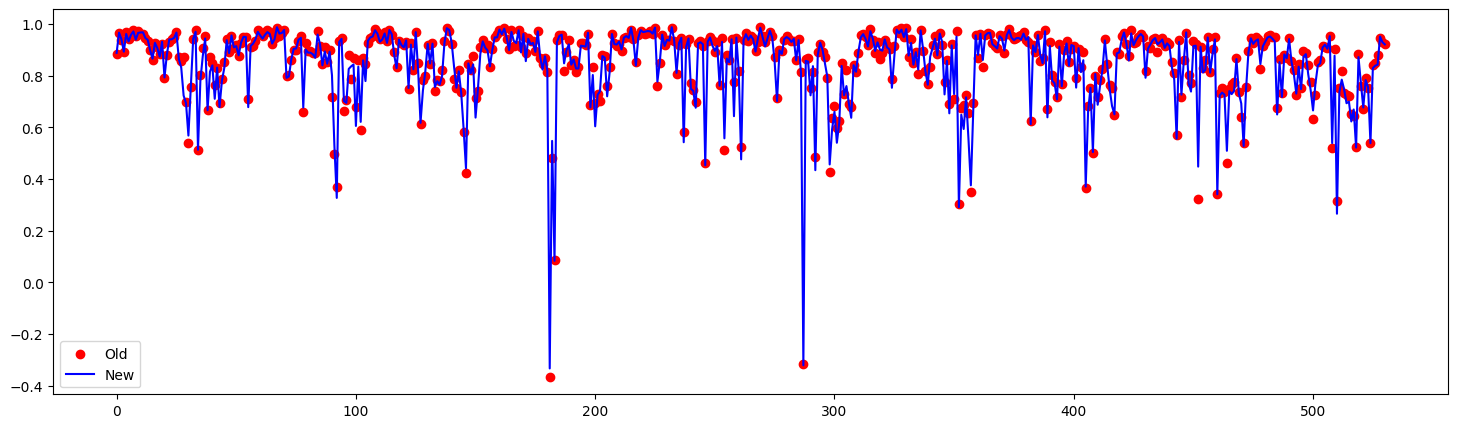

In [29]:
import pandas as pd

df= pd.read_csv("/home/s0shar47/scratch/Recharge_reitz/recharge_vs_tiff_annual_values.csv")
df2= pd.read_csv("/home/s0shar47/scratch/Recharge_reitz/recharge_vs_tiff_correlation.csv")

plt.figure(figsize=(18,5))
plt.scatter(range(531),df2[df2['MODEL']=='HBV']['r_old'], label= 'Old', color='red')
plt.plot(df2[df2['MODEL']=='HBV']['r_new'], label= 'New', color='blue')
plt.legend()
plt.show()

In [33]:
# ============================================================
# BASIN-BASED SPATIAL AVERAGE OF RC_eff TIFFs FOR EACH GAUGE
#
# Years: 2000 - 2013
#
# For each CAMELS basin:
#   1. Calculate spatial mean of RC_eff_YEAR.tif
#   2. Match basin to gauge using GAGEID
#   3. Assign basin mean to gauge
#
# Output:
#   - One row per gauge
#   - One column per year
#   - Long-format CSV
#   - Wide-format CSV
#   - Gauge/basin GeoPackage
# ============================================================

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio

from rasterstats import zonal_stats


# ============================================================
# 1. PATHS
# ============================================================

BASIN_SHP = (
    "/scratch/data/CAMELS_FORCING/"
    "basin_dataset_public_v1p2/shapefiles/"
    "CAMELS_671_basins.shp"
)

GAUGE_CSV = (
    "/home/s0shar47/scratch/salil/DPL/"
    "dPL_Hydro_SNTEMP/config/gauge_loc.csv"
)

RASTER_BASE = (
    "/home/s0shar47/scratch/Recharge_reitz"
)

OUTPUT_DIR = (
    "/home/s0shar47/scratch/Recharge_reitz/"
    "gauge_basin_average"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ============================================================
# 2. YEARS
# ============================================================

YEARS = list(range(2000, 2014))


# ============================================================
# 3. READ CAMELS BASINS
# ============================================================

print("\n" + "=" * 80)
print("STEP 1: READING CAMELS BASINS")
print("=" * 80)

basins = gpd.read_file(
    BASIN_SHP
)

print(
    f"Number of basins: {len(basins)}"
)

print(
    f"Basin CRS: {basins.crs}"
)

print(
    "Basin columns:"
)

print(
    basins.columns.tolist()
)


# ============================================================
# 4. CHECK GAGEID
# ============================================================

if "GAGEID" not in basins.columns:

    raise ValueError(
        "GAGEID column not found in CAMELS basin shapefile."
    )


# ------------------------------------------------------------
# Convert GAGEID to integer
# ------------------------------------------------------------

basins["GAGEID"] = pd.to_numeric(
    basins["GAGEID"],
    errors="coerce"
)

print(
    f"\nMissing GAGEID values: "
    f"{basins['GAGEID'].isna().sum()}"
)


# Remove basins without GAGEID

basins = basins[
    basins["GAGEID"].notna()
].copy()

basins["GAGEID"] = (
    basins["GAGEID"]
    .astype(int)
)


# ============================================================
# 5. CHECK UNIQUE BASINS
# ============================================================

print(
    f"Basins after removing missing GAGEID: "
    f"{len(basins)}"
)

print(
    f"Unique GAGEIDs: "
    f"{basins['GAGEID'].nunique()}"
)


if basins["GAGEID"].duplicated().any():

    duplicated = (
        basins[
            basins["GAGEID"].duplicated(
                keep=False
            )
        ]["GAGEID"]
        .unique()
    )

    raise ValueError(
        f"Duplicate GAGEIDs found: {duplicated}"
    )


# ============================================================
# 6. FIX INVALID GEOMETRIES
# ============================================================

print("\nChecking basin geometries...")

invalid_before = (
    ~basins.geometry.is_valid
).sum()

print(
    f"Invalid geometries before repair: "
    f"{invalid_before}"
)

if invalid_before > 0:

    basins["geometry"] = (
        basins.geometry.make_valid()
    )

invalid_after = (
    ~basins.geometry.is_valid
).sum()

print(
    f"Invalid geometries after repair: "
    f"{invalid_after}"
)


# ============================================================
# 7. READ GAUGE LOCATIONS
# ============================================================

print("\n" + "=" * 80)
print("STEP 2: READING GAUGE LOCATIONS")
print("=" * 80)

locations = pd.read_csv(
    GAUGE_CSV
)

locations= locations.rename(columns={'GAGE_ID':'GAGEID'})

print(
    f"Number of gauges: {len(locations)}"
)

print(
    "Gauge columns:"
)

print(
    locations.columns.tolist()
)


# ============================================================
# 8. CREATE GAUGE GEODATAFRAME
# ============================================================

locations_gdf = gpd.GeoDataFrame(

    locations.copy(),

    geometry=gpd.points_from_xy(
        locations["LONG"],
        locations["LAT"]
    ),

    crs="EPSG:4326"
)

print(
    f"\nGauge CRS: {locations_gdf.crs}"
)


# ============================================================
# 9. MATCH GAUGES TO BASINS USING GAGEID
# ============================================================

print("\n" + "=" * 80)
print("STEP 3: MATCHING GAUGES TO CAMELS BASINS")
print("=" * 80)


# ------------------------------------------------------------
# IMPORTANT:
# Your gauge CSV must contain GAGEID.
#
# If it uses another column name, change it here.
# ------------------------------------------------------------

if "GAGEID" not in locations_gdf.columns:

    raise ValueError(
        "GAGEID column not found in gauge_loc.csv"
    )


# Convert gauge GAGEID to integer

locations_gdf["GAGEID"] = pd.to_numeric(
    locations_gdf["GAGEID"],
    errors="coerce"
)

locations_gdf = locations_gdf[
    locations_gdf["GAGEID"].notna()
].copy()

locations_gdf["GAGEID"] = (
    locations_gdf["GAGEID"]
    .astype(int)
)


# ============================================================
# 10. MATCH USING GAGEID
# ============================================================

locations_with_basin = locations_gdf.merge(

    basins[
        [
            "GAGEID"
        ]
    ],

    on="GAGEID",

    how="left",

    indicator=True,

    suffixes=("", "_basin"),

    validate="one_to_one"
)


# Since GAGEID already exists, create explicit match flag

locations_with_basin["BASIN_MATCH"] = (
    locations_with_basin["_merge"]
    == "both"
)

locations_with_basin = (
    locations_with_basin
    .drop(columns=["_merge"])
)


print(
    f"Gauge records: "
    f"{len(locations_with_basin)}"
)

print(
    f"Matched gauges: "
    f"{locations_with_basin['BASIN_MATCH'].sum()}"
)

print(
    f"Unmatched gauges: "
    f"{(~locations_with_basin['BASIN_MATCH']).sum()}"
)


# ============================================================
# 11. CHECK WHICH BASINS MATCH FORCING/GAGES
# ============================================================

matched_gageids = set(
    locations_with_basin.loc[
        locations_with_basin["BASIN_MATCH"],
        "GAGEID"
    ]
)

basin_gageids = set(
    basins["GAGEID"]
)

print(
    f"Unique basin GAGEIDs: "
    f"{len(basin_gageids)}"
)

print(
    f"Unique matched GAGEIDs: "
    f"{len(matched_gageids)}"
)


# ============================================================
# 12. SAVE GAUGE-BASIN ASSIGNMENT
# ============================================================

gauge_basin_csv = os.path.join(

    OUTPUT_DIR,

    "gauge_basin_assignment.csv"
)

locations_with_basin.drop(
    columns=["geometry"]
).to_csv(

    gauge_basin_csv,

    index=False
)

print(
    f"\nGauge-basin assignment saved:"
)

print(
    gauge_basin_csv
)


# ============================================================
# 13. CREATE RESULTS DATAFRAME
# ============================================================

results = (
    locations_with_basin
    .drop(columns=["geometry"])
    .copy()
)


# ============================================================
# 14. PROCESS EACH YEAR
# ============================================================

print("\n" + "=" * 80)
print("STEP 4: PROCESSING ANNUAL TIFF FILES")
print("=" * 80)


for year in YEARS:

    print("\n")
    print("-" * 80)

    print(
        f"YEAR {year}"
    )

    print("-" * 80)


    # ========================================================
    # TIFF PATH
    # ========================================================

    tif_path = (
        f"{RASTER_BASE}/"
        f"EffRecharge_{year}/"
        f"{year}/"
        f"RC_eff_{year}.tif"
    )

    print(
        f"TIFF:\n{tif_path}"
    )


    # ========================================================
    # CHECK TIFF EXISTS
    # ========================================================

    if not os.path.isfile(
        tif_path
    ):

        print(
            f"WARNING: TIFF not found for {year}"
        )

        results[
            f"mean_{year}"
        ] = np.nan

        continue


    # ========================================================
    # OPEN TIFF
    # ========================================================

    with rasterio.open(
        tif_path
    ) as src:

        print(
            f"Raster CRS: {src.crs}"
        )

        print(
            f"Raster dimensions: "
            f"{src.width} x {src.height}"
        )

        print(
            f"Raster resolution: "
            f"{src.res}"
        )

        print(
            f"Raster NoData: "
            f"{src.nodata}"
        )

        raster_crs = src.crs
        raster_nodata = src.nodata


    # ========================================================
    # REPROJECT BASINS TO RASTER CRS
    # ========================================================

    basins_raster = (
        basins.to_crs(
            raster_crs
        )
    )


    # ========================================================
    # CALCULATE BASIN ZONAL MEANS
    # ========================================================

    print(
        "Calculating spatial mean for each CAMELS basin..."
    )


    stats = zonal_stats(

        basins_raster.geometry,

        tif_path,

        stats=[
            "mean"
        ],

        nodata=raster_nodata,

        all_touched=False
    )


    # ========================================================
    # EXTRACT MEAN VALUES
    # ========================================================

    basin_means = np.array(

        [

            (
                stat["mean"]

                if stat["mean"] is not None

                else np.nan
            )

            for stat in stats
        ],

        dtype=float
    )


    # ========================================================
    # CREATE BASIN LOOKUP
    # ========================================================

    basin_lookup = pd.DataFrame({

        "GAGEID":
            basins_raster["GAGEID"].values,

        f"mean_{year}":
            basin_means

    })


    # ========================================================
    # CHECK GAGEID UNIQUENESS
    # ========================================================

    if basin_lookup[
        "GAGEID"
    ].duplicated().any():

        raise ValueError(
            "Duplicate GAGEIDs found in basin lookup."
        )


    # ========================================================
    # CHECK BASIN RESULTS
    # ========================================================

    valid_basins = np.isfinite(
        basin_means
    ).sum()

    missing_basins = np.isnan(
        basin_means
    ).sum()


    print(
        f"Basins with valid mean: "
        f"{valid_basins}"
    )

    print(
        f"Basins without valid mean: "
        f"{missing_basins}"
    )


    # ========================================================
    # MERGE BASIN MEAN TO GAUGES
    # ========================================================

    results = results.merge(

        basin_lookup,

        on="GAGEID",

        how="left",

        validate="one_to_one"
    )


    # ========================================================
    # VERIFY GAUGE COUNT
    # ========================================================

    if len(results) != len(
        locations_with_basin
    ):

        raise ValueError(
            f"Number of gauge rows changed "
            f"after processing {year}."
        )


    # ========================================================
    # CHECK GAUGE VALUES
    # ========================================================

    valid_gauges = (
        results[
            f"mean_{year}"
        ]
        .notna()
        .sum()
    )

    missing_gauges = (
        results[
            f"mean_{year}"
        ]
        .isna()
        .sum()
    )


    print(
        f"Gauges with valid {year} value: "
        f"{valid_gauges}"
    )

    print(
        f"Gauges with missing {year} value: "
        f"{missing_gauges}"
    )


    print(
        f"Finished {year}"
    )


# ============================================================
# 15. FINAL CHECK
# ============================================================

print("\n" + "=" * 80)
print("STEP 5: FINAL DATA CHECK")
print("=" * 80)


print(
    f"Number of gauges: "
    f"{len(results)}"
)


print(
    f"Number of columns: "
    f"{len(results.columns)}"
)


year_columns = [
    f"mean_{year}"
    for year in YEARS
]


print(
    "\nAnnual columns:"
)

for year in YEARS:

    column = f"mean_{year}"

    if column in results.columns:

        n_valid = (
            results[column]
            .notna()
            .sum()
        )

        n_missing = (
            results[column]
            .isna()
            .sum()
        )

        print(
            f"{year}: "
            f"{n_valid} valid, "
            f"{n_missing} missing"
        )


# ============================================================
# 16. SAVE WIDE FORMAT
# ============================================================

print("\n" + "=" * 80)
print("STEP 6: SAVING WIDE FORMAT")
print("=" * 80)


wide_csv = os.path.join(

    OUTPUT_DIR,

    "RC_eff_basin_mean_2000_2013_wide.csv"
)


results.to_csv(

    wide_csv,

    index=False
)


print(
    f"Saved:\n{wide_csv}"
)


# ============================================================
# 17. CREATE LONG FORMAT
# ============================================================

print("\n" + "=" * 80)
print("STEP 7: CREATING LONG FORMAT")
print("=" * 80)


id_columns = [
    c
    for c in results.columns
    if c not in year_columns
]


results_long = results.melt(

    id_vars=id_columns,

    value_vars=year_columns,

    var_name="YEAR",

    value_name="RC_eff_basin_mean"
)


results_long["YEAR"] = (

    results_long["YEAR"]

    .str.replace(
        "mean_",
        "",
        regex=False
    )

    .astype(int)
)


# ============================================================
# 18. SAVE LONG FORMAT
# ============================================================

long_csv = os.path.join(

    OUTPUT_DIR,

    "RC_eff_basin_mean_2000_2013_long.csv"
)


results_long.to_csv(

    long_csv,

    index=False
)


print(
    f"Saved:\n{long_csv}"
)


# ============================================================
# 19. SAVE GEOPACKAGE
# ============================================================

print("\n" + "=" * 80)
print("STEP 8: SAVING GEOPACKAGE")
print("=" * 80)


results_gdf = (
    locations_with_basin.copy()
)


# ------------------------------------------------------------
# Add annual values
# ------------------------------------------------------------

for year in YEARS:

    column = f"mean_{year}"

    if column not in results.columns:

        continue


    values = results[
        [
            "GAGEID",
            column
        ]
    ].copy()


    results_gdf = results_gdf.merge(

        values,

        on="GAGEID",

        how="left",

        validate="one_to_one"
    )


# ============================================================
# SAVE GEOPACKAGE
# ============================================================

gpkg_path = os.path.join(

    OUTPUT_DIR,

    "RC_eff_basin_mean_2000_2013.gpkg"
)


results_gdf.to_file(

    gpkg_path,

    layer="gauge_basin_recharge",

    driver="GPKG"
)


print(
    f"Saved:\n{gpkg_path}"
)


# ============================================================
# 20. REMOVE INTERNAL COLUMNS
# ============================================================

results_clean = results.drop(

    columns=[
        "BASIN_MATCH"
    ],

    errors="ignore"
)


results_long_clean = results_long.drop(

    columns=[
        "BASIN_MATCH"
    ],

    errors="ignore"
)


# Re-save cleaned CSVs

results_clean.to_csv(

    wide_csv,

    index=False
)


results_long_clean.to_csv(

    long_csv,

    index=False
)


# ============================================================
# 21. DISPLAY SAMPLE
# ============================================================

print("\n" + "=" * 80)
print("SAMPLE RESULTS")
print("=" * 80)


print(
    results_clean.head()
    .to_string(index=False)
)


# ============================================================
# 22. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("PROCESSING COMPLETE")
print("=" * 80)


print(
    f"Number of gauges: "
    f"{len(results_clean)}"
)

print(
    f"Years: "
    f"{YEARS[0]} - {YEARS[-1]}"
)


print("\nOutput files:")

print(
    f"1. Gauge-basin assignment:\n"
    f"   {gauge_basin_csv}"
)

print(
    f"\n2. Wide CSV:\n"
    f"   {wide_csv}"
)

print(
    f"\n3. Long CSV:\n"
    f"   {long_csv}"
)

print(
    f"\n4. GeoPackage:\n"
    f"   {gpkg_path}"
)


print("\n" + "=" * 80)
print("DONE")
print("=" * 80)



STEP 1: READING CAMELS BASINS
Number of basins: 671
Basin CRS: EPSG:5070
Basin columns:
['GAGEID', 'Dissolve', 'POI_ID', 'PROD_UNIT', 'hru_id_pro', 'hru_id_reg', 'hru_id_loc', 'hru_id', 'hru_x', 'hru_y', 'hru_area', 'hru_elev', 'hru_slope', 'hru_aspect', 'asp_sin', 'asp_cos', 'jh_coef_hr', 'tmin_adj', 'tmax_adj', 'snarea_thr', 'hru_deplcr', 'soil_moist', 'soil_rechr', 'soil_type', 'cov_type', 'VALUE_0', 'VALUE_1', 'VALUE_2', 'VALUE_3', 'covden_sum', 'leaf_loss', 'covden_win', 'rad_trncf', 'srain_intc', 'wrain_intc', 'snow_intcp', 'hru_percen', 'soil2gw_ma', 'ssr2gw_rat', 'fastcoef_l', 'slowcoef_l', 'gwflow_coe', 'dprst_seep', 'dprst_se_1', 'dprst_flow', 'r_k_perm_w', 'r_junk', 'hru_long', 'hru_lat', 'dprst_area', 'sro_to_dpr', 'hru_segmen', 'Shape_Leng', 'Shape_Area', 'geometry']

Missing GAGEID values: 0
Basins after removing missing GAGEID: 671
Unique GAGEIDs: 671

Checking basin geometries...
Invalid geometries before repair: 0
Invalid geometries after repair: 0

STEP 2: READING GA

In [ ]:
import pandas as pd

df= pd.read_csv("/home/s0shar47/scratch/Recharge_reitz/recharge_vs_tiff_annual_values.csv")
df2= pd.read_csv("/home/s0shar47/scratch/Recharge_reitz/recharge_vs_tiff_correlation.csv")

plt.figure(figsize=(18,5))
plt.scatter(range(531),df2[df2['MODEL']=='HBV']['r_old'], label= 'Old', color='red')
plt.plot(df2[df2['MODEL']=='HBV']['r_new'], label= 'New', color='blue')
plt.legend()
plt.show()

TIFF basins: 671

METHOD=USGS | MODEL=HBV | TEST=PUR

Region 1
Basins: 92

Region 2
Basins: 95

Region 3
Basins: 93

Region 4
Basins: 51

Region 5
Basins: 68

Region 6
Basins: 60

Region 7
Basins: 72

Region 8
Missing file -- skipping

Matched basin records: 531

Old r:
count    531.000000
mean       0.846483
std        0.162477
min       -0.404906
25%        0.804228
50%        0.899526
75%        0.944303
max        0.991894
Name: r_old, dtype: float64

New r:
count    531.000000
mean       0.847560
std        0.163736
min       -0.399171
25%        0.808382
50%        0.903410
75%        0.945037
max        0.989742
Name: r_new, dtype: float64


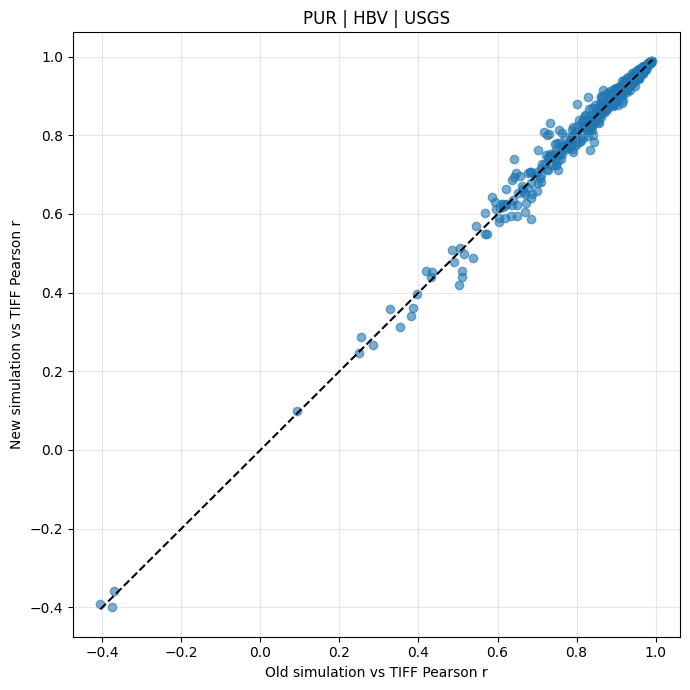


Saved:
/home/s0shar47/scratch/Recharge_reitz/Basin_wise/recharge_vs_tiff_correlation_PUR_HBV_USGS.csv
/home/s0shar47/scratch/Recharge_reitz/Basin_wise/recharge_vs_tiff_annual_values_PUR_HBV_USGS.csv

METHOD=USGS | MODEL=HBV_capillary | TEST=PUR

Region 1
Basins: 92

Region 2
Basins: 95

Region 3
Basins: 93

Region 4
Basins: 51

Region 5
Basins: 68

Region 6
Basins: 60

Region 7
Basins: 72

Region 8
Missing file -- skipping

Matched basin records: 531

Old r:
count    531.000000
mean       0.858637
std        0.156077
min       -0.361277
25%        0.819930
50%        0.909850
75%        0.953104
max        0.993700
Name: r_old, dtype: float64

New r:
count    531.000000
mean       0.859326
std        0.152007
min       -0.345175
25%        0.820492
50%        0.908890
75%        0.951565
max        0.991773
Name: r_new, dtype: float64


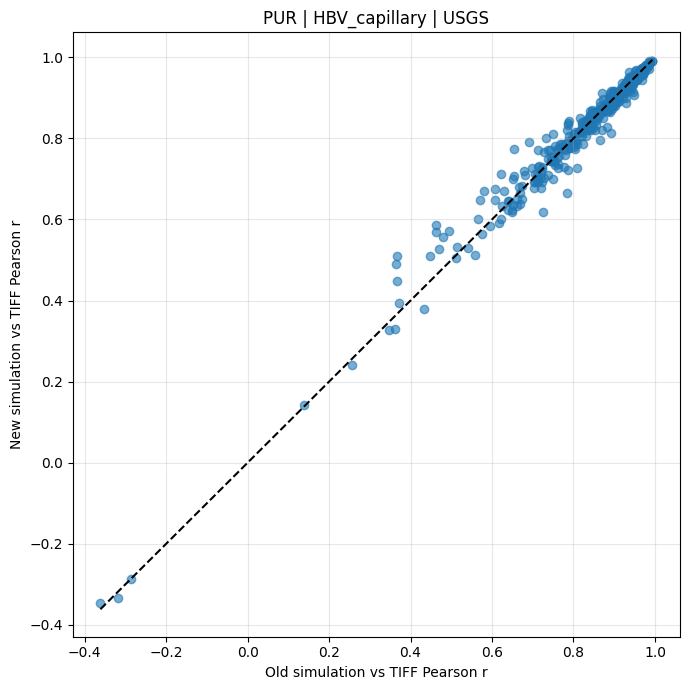


Saved:
/home/s0shar47/scratch/Recharge_reitz/Basin_wise/recharge_vs_tiff_correlation_PUR_HBV_capillary_USGS.csv
/home/s0shar47/scratch/Recharge_reitz/Basin_wise/recharge_vs_tiff_annual_values_PUR_HBV_capillary_USGS.csv

METHOD=Furey | MODEL=HBV | TEST=PUR

Region 1
Basins: 92

Region 2
Basins: 95

Region 3
Basins: 93

Region 4
Basins: 51

Region 5
Basins: 68

Region 6
Basins: 60

Region 7
Basins: 72

Region 8
Missing file -- skipping

Matched basin records: 531

Old r:
count    531.000000
mean       0.846483
std        0.162477
min       -0.404906
25%        0.804228
50%        0.899526
75%        0.944303
max        0.991894
Name: r_old, dtype: float64

New r:
count    531.000000
mean       0.842670
std        0.164974
min       -0.397459
25%        0.805453
50%        0.900937
75%        0.941831
max        0.991707
Name: r_new, dtype: float64


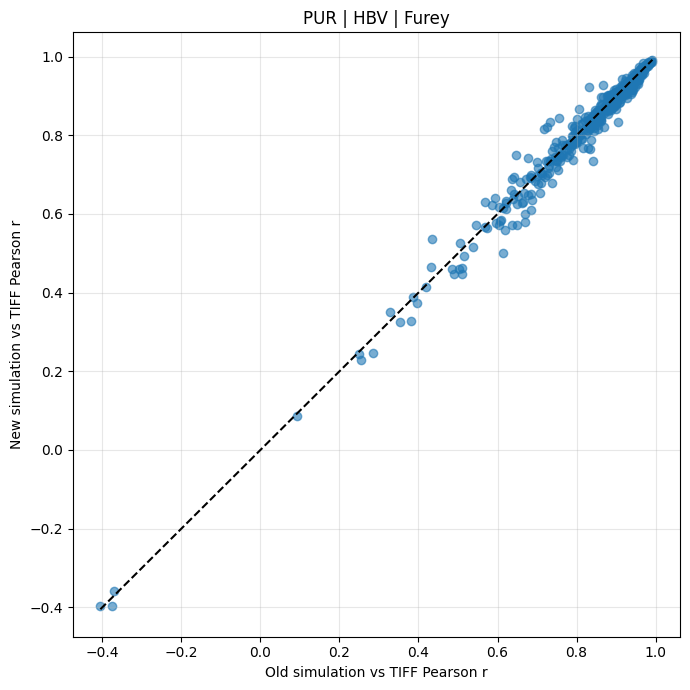


Saved:
/home/s0shar47/scratch/Recharge_reitz/Basin_wise/recharge_vs_tiff_correlation_PUR_HBV_Furey.csv
/home/s0shar47/scratch/Recharge_reitz/Basin_wise/recharge_vs_tiff_annual_values_PUR_HBV_Furey.csv

METHOD=Furey | MODEL=HBV_capillary | TEST=PUR

Region 1
Basins: 92

Region 2
Basins: 95

Region 3
Basins: 93

Region 4
Basins: 51

Region 5
Basins: 68

Region 6
Basins: 60

Region 7
Basins: 72

Region 8
Missing file -- skipping

Matched basin records: 531

Old r:
count    531.000000
mean       0.858637
std        0.156077
min       -0.361277
25%        0.819930
50%        0.909850
75%        0.953104
max        0.993700
Name: r_old, dtype: float64

New r:
count    531.000000
mean       0.852926
std        0.156540
min       -0.350375
25%        0.814997
50%        0.902497
75%        0.948354
max        0.991227
Name: r_new, dtype: float64


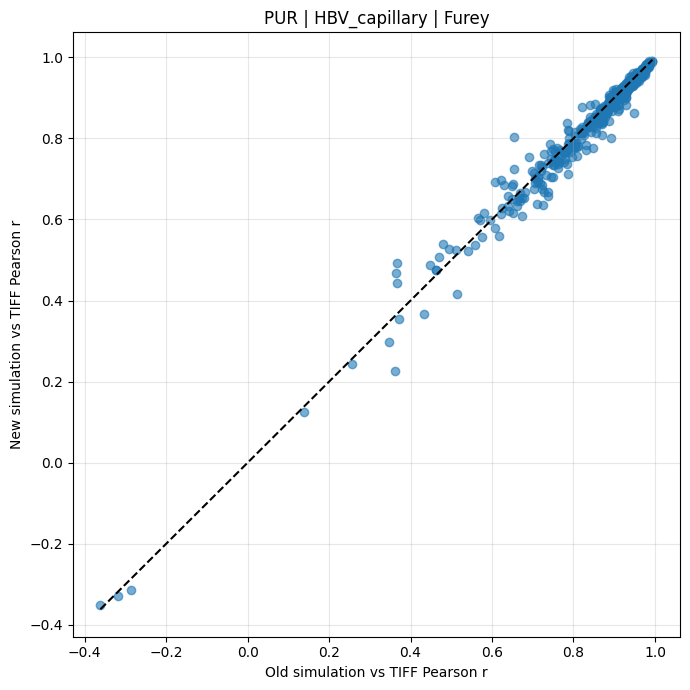


Saved:
/home/s0shar47/scratch/Recharge_reitz/Basin_wise/recharge_vs_tiff_correlation_PUR_HBV_capillary_Furey.csv
/home/s0shar47/scratch/Recharge_reitz/Basin_wise/recharge_vs_tiff_annual_values_PUR_HBV_capillary_Furey.csv

METHOD=Eckhardt | MODEL=HBV | TEST=PUR

Region 1
Basins: 92

Region 2
Basins: 95

Region 3
Basins: 93

Region 4
Basins: 51

Region 5
Basins: 68

Region 6
Basins: 60

Region 7
Basins: 72

Region 8
Missing file -- skipping

Matched basin records: 531

Old r:
count    531.000000
mean       0.846483
std        0.162477
min       -0.404906
25%        0.804228
50%        0.899526
75%        0.944303
max        0.991894
Name: r_old, dtype: float64

New r:
count    531.000000
mean       0.844774
std        0.162668
min       -0.401771
25%        0.807967
50%        0.898520
75%        0.942315
max        0.992039
Name: r_new, dtype: float64


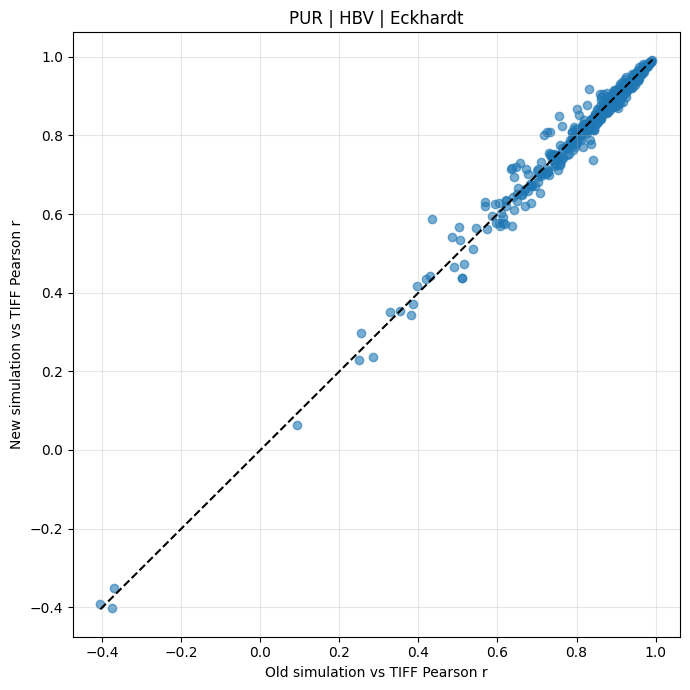


Saved:
/home/s0shar47/scratch/Recharge_reitz/Basin_wise/recharge_vs_tiff_correlation_PUR_HBV_Eckhardt.csv
/home/s0shar47/scratch/Recharge_reitz/Basin_wise/recharge_vs_tiff_annual_values_PUR_HBV_Eckhardt.csv

METHOD=Eckhardt | MODEL=HBV_capillary | TEST=PUR

Region 1
Basins: 92

Region 2
Basins: 95

Region 3
Basins: 93

Region 4
Basins: 51

Region 5
Basins: 68

Region 6
Basins: 60

Region 7
Basins: 72

Region 8
Missing file -- skipping

Matched basin records: 531

Old r:
count    531.000000
mean       0.858637
std        0.156077
min       -0.361277
25%        0.819930
50%        0.909850
75%        0.953104
max        0.993700
Name: r_old, dtype: float64

New r:
count    531.000000
mean       0.855649
std        0.154888
min       -0.362064
25%        0.811413
50%        0.906120
75%        0.949873
max        0.991239
Name: r_new, dtype: float64


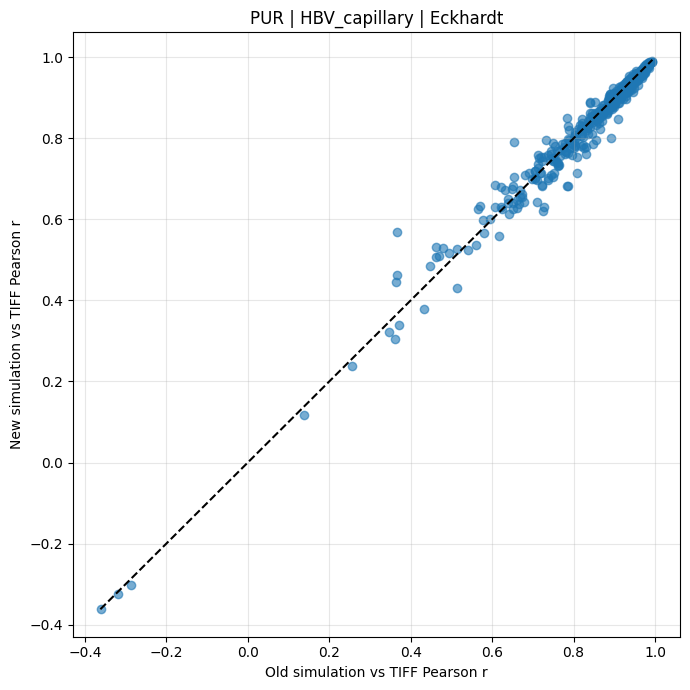


Saved:
/home/s0shar47/scratch/Recharge_reitz/Basin_wise/recharge_vs_tiff_correlation_PUR_HBV_capillary_Eckhardt.csv
/home/s0shar47/scratch/Recharge_reitz/Basin_wise/recharge_vs_tiff_annual_values_PUR_HBV_capillary_Eckhardt.csv

METHOD=LocalHYSEP | MODEL=HBV | TEST=PUR

Region 1
Basins: 92

Region 2
Basins: 95

Region 3
Basins: 93

Region 4
Basins: 51

Region 5
Basins: 68

Region 6
Basins: 60

Region 7
Basins: 72

Region 8
Missing file -- skipping

Matched basin records: 531

Old r:
count    531.000000
mean       0.846483
std        0.162477
min       -0.404906
25%        0.804228
50%        0.899526
75%        0.944303
max        0.991894
Name: r_old, dtype: float64

New r:
count    531.000000
mean       0.844161
std        0.163375
min       -0.439800
25%        0.806089
50%        0.899261
75%        0.941706
max        0.991318
Name: r_new, dtype: float64


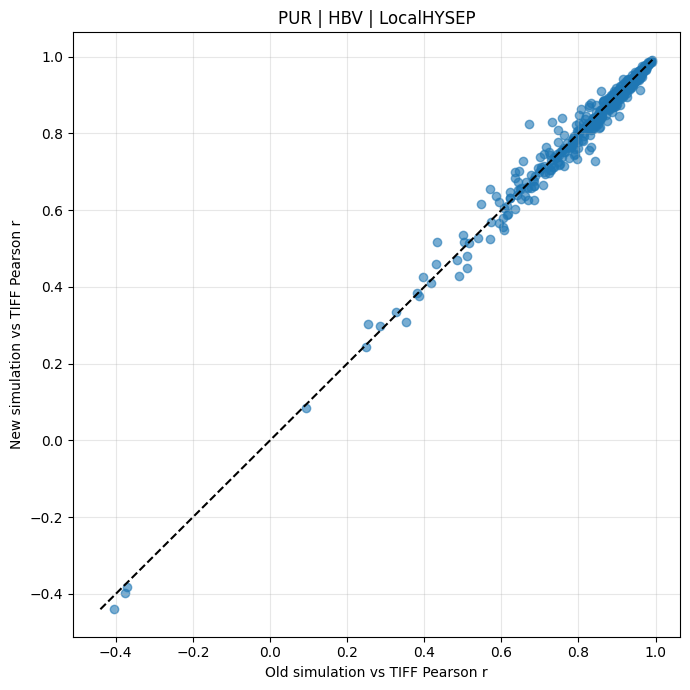


Saved:
/home/s0shar47/scratch/Recharge_reitz/Basin_wise/recharge_vs_tiff_correlation_PUR_HBV_LocalHYSEP.csv
/home/s0shar47/scratch/Recharge_reitz/Basin_wise/recharge_vs_tiff_annual_values_PUR_HBV_LocalHYSEP.csv

METHOD=LocalHYSEP | MODEL=HBV_capillary | TEST=PUR

Region 1
Basins: 92

Region 2
Basins: 95

Region 3
Basins: 93

Region 4
Basins: 51

Region 5
Basins: 68

Region 6
Basins: 60

Region 7
Basins: 72

Region 8
Missing file -- skipping

Matched basin records: 531

Old r:
count    531.000000
mean       0.858637
std        0.156077
min       -0.361277
25%        0.819930
50%        0.909850
75%        0.953104
max        0.993700
Name: r_old, dtype: float64

New r:
count    531.000000
mean       0.857234
std        0.153763
min       -0.332141
25%        0.822896
50%        0.909254
75%        0.950320
max        0.995331
Name: r_new, dtype: float64


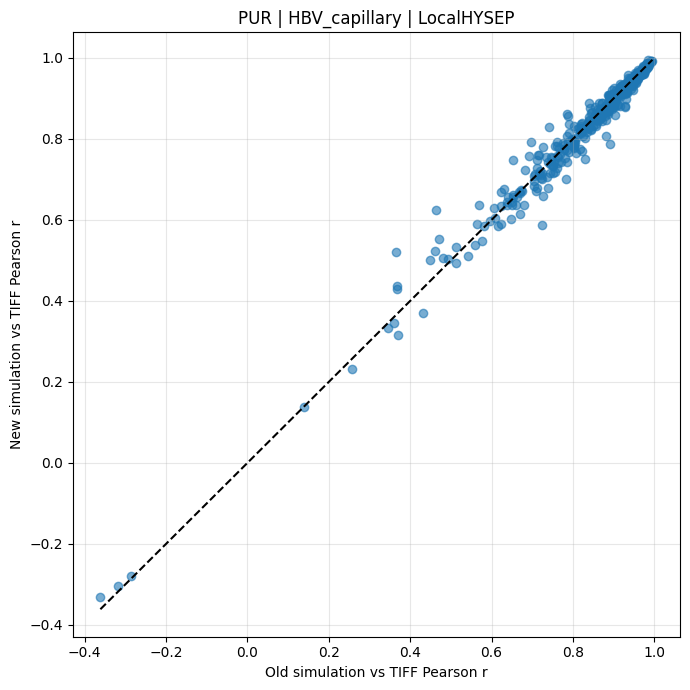


Saved:
/home/s0shar47/scratch/Recharge_reitz/Basin_wise/recharge_vs_tiff_correlation_PUR_HBV_capillary_LocalHYSEP.csv
/home/s0shar47/scratch/Recharge_reitz/Basin_wise/recharge_vs_tiff_annual_values_PUR_HBV_capillary_LocalHYSEP.csv


In [40]:
# ============================================================
# SIMULATED RECHARGE vs BASIN TIFF RECHARGE
# Annual mean: 2000-2013
# GAGEID matching is done as INTEGER
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr


# ============================================================
# SETTINGS
# ============================================================

objectives = ["Single", "Multi"]
methods = ["USGS", "Furey", "Eckhardt", "LocalHYSEP"]

START_YEAR = 2000
END_YEAR = 2013
YEARS = np.arange(START_YEAR, END_YEAR + 1)

test = "PUR"

models = [
    "HBV",
    "HBV_capillary",
    # "marrmot_PRMS"
]

dates = pd.date_range(
    "1981-01-01",
    "2014-12-31",
    freq="D"
)

OUTPUT_DIR = (
    "/home/s0shar47/scratch/"
    "Recharge_reitz/Basin_wise"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================================================
# TIFF BASIN RECHARGE
# ============================================================

TIFF_CSV = (
    "/home/s0shar47/scratch/"
    "Recharge_reitz/gauge_basin_average/"
    "RC_eff_basin_mean_2000_2013_wide.csv"
)

tiff_data = pd.read_csv(TIFF_CSV)

if "GAGEID" in tiff_data.columns:
    ID_COL = "GAGEID"
elif "STAID" in tiff_data.columns:
    ID_COL = "STAID"
elif "ID" in tiff_data.columns:
    ID_COL = "ID"
else:
    raise ValueError("No GAGEID/STAID/ID column found.")


# Force GAGEIDs to integer
tiff_data["GAGEID_INT"] = pd.to_numeric(
    tiff_data[ID_COL],
    errors="coerce"
)

tiff_data = tiff_data[
    tiff_data["GAGEID_INT"].notna()
].copy()

tiff_data["GAGEID_INT"] = (
    tiff_data["GAGEID_INT"]
    .astype(np.int64)
)


# Check uniqueness
if tiff_data["GAGEID_INT"].duplicated().any():
    raise ValueError("Duplicate GAGEIDs in TIFF CSV.")


# GAGEID -> annual TIFF recharge
tiff_lookup = {
    int(row["GAGEID_INT"]): np.array(
        [row[f"mean_{year}"] for year in YEARS],
        dtype=float
    )
    for _, row in tiff_data.iterrows()
}

print("TIFF basins:", len(tiff_lookup))


# ============================================================
# FUNCTIONS
# ============================================================

def get_dyn(model):

    if model == "HBV":
        return "parBETA_parBETAET_"

    if model == "HBV_capillary":
        return "parBETA_parBETAET_parK0_parUZL_"

    if model == "marrmot_PRMS":
        return "alpha_cgw_scx_tt_"

    raise ValueError(f"Unknown model: {model}")


def annual_means(recharge):

    recharge = np.asarray(
        recharge,
        dtype=float
    )

    # Expected input: (time, basins)
    if recharge.shape[0] == len(dates):
        recharge = recharge.T

    elif recharge.shape[1] != len(dates):
        raise ValueError(
            f"Unexpected recharge shape: {recharge.shape}"
        )

    # Now: (basins, time)
    annual = np.full(
        (recharge.shape[0], len(YEARS)),
        np.nan
    )

    for j, year in enumerate(YEARS):

        mask = dates.year == year

        annual[:, j] = np.nanmean(
            recharge[:, mask],
            axis=1
        )

    return annual


def correlation(x, y):

    valid = (
        np.isfinite(x)
        & np.isfinite(y)
    )

    if valid.sum() < 3:
        return np.nan, np.nan, valid.sum()

    x = x[valid]
    y = y[valid]

    if np.std(x) == 0 or np.std(y) == 0:
        return np.nan, np.nan, len(x)

    r, p = pearsonr(x, y)

    return r, p, len(x)


# ============================================================
# LOOP METHODS
# ============================================================

for method in methods:

    for model in models:

        correlation_results = []
        annual_results = []

        dyn = get_dyn(model)

        print("\n" + "=" * 80)
        print(
            f"METHOD={method} | MODEL={model} | TEST={test}"
        )
        print("=" * 80)


        # ----------------------------------------------------
        # REGIONS
        # ----------------------------------------------------

        n_regions = 11 if test == "PUB" else 8


        # ----------------------------------------------------
        # LOOP REGIONS
        # ----------------------------------------------------

        for region in range(1, n_regions + 1):

            print(
                f"\nRegion {region}"
            )


            # =================================================
            # PATHS
            # =================================================

            if test == "PUB":

                folder = (
                    f"/home/s0shar47/scratch/"
                    f"OUTPUTS_Paper1/PUB/"
                    f"{method}_{objectives[1]}/"
                    f"{region}/"
                )

                sfolder = (
                    f"/home/s0shar47/scratch/"
                    f"OUTPUTS_Paper1/PUB/"
                    f"OUTPUTS_PUB_{objectives[0]}/"
                    f"{region}/"
                )

                forcing_path = (
                    f"/scratch/data/"
                    f"PUB_DATA/test/{region}/"
                    f"daymet_19800101_20141231_"
                    f"forcing_671_baseflow_mmday.npy"
                )

            else:

                folder = (
                    f"/home/s0shar47/scratch/"
                    f"OUTPUTS_Paper1/PUR/"
                    f"{method}_{objectives[1]}/"
                    f"Region_{region}/"
                )

                sfolder = (
                    f"/home/s0shar47/scratch/"
                    f"OUTPUTS_Paper1/PUR/"
                    f"OUTPUTS_PUR_{objectives[0]}/"
                    f"Region_{region}/"
                )

                forcing_path = (
                    f"/scratch/data/"
                    f"PUR_DATA/test/Region_{region}/"
                    f"daymet_19800101_20141231_"
                    f"forcing_671_baseflow_mmday.npy"
                )


            run_name = (
                f"LSTM_{model}_"
                f"E50_R365_B100_H256_"
                f"tr1989_1999_n16_111111"
            )


            old_path = os.path.join(
                sfolder,
                run_name,
                dyn,
                "ts1980_2014",
                "recharge.npy"
            )

            new_path = os.path.join(
                folder,
                run_name,
                dyn,
                "ts1980_2014",
                "recharge.npy"
            )


            # =================================================
            # CHECK FILES
            # =================================================

            if not all(
                os.path.exists(p)
                for p in [
                    old_path,
                    new_path,
                    forcing_path
                ]
            ):

                print("Missing file -- skipping")
                continue


            # =================================================
            # LOAD
            # =================================================

            forcing = np.load(
                forcing_path
            )

            sim_old = np.squeeze(
                np.load(old_path)
            )

            sim_new = np.squeeze(
                np.load(new_path)
            )


            # =================================================
            # ANNUAL MEANS
            # =================================================

            annual_old = annual_means(
                sim_old
            )

            annual_new = annual_means(
                sim_new
            )


            n_basins = annual_old.shape[0]

            print(
                f"Basins: {n_basins}"
            )


            # =================================================
            # LOOP BASINS
            # =================================================

            for basin in range(n_basins):

                # GAGEID is forcing[:, 0, 14]
                gauge_raw = forcing[
                    basin,
                    0,
                    14
                ]

                if not np.isfinite(gauge_raw):
                    continue

                # IMPORTANT: integer matching
                gauge = int(gauge_raw)


                # ------------------------------------------------
                # TIFF MATCH
                # ------------------------------------------------

                if gauge not in tiff_lookup:
                    continue

                tiff_series = tiff_lookup[gauge]

                old_series = annual_old[
                    basin
                ]

                new_series = annual_new[
                    basin
                ]


                # ------------------------------------------------
                # CORRELATIONS
                # ------------------------------------------------

                r_old, p_old, n_old = correlation(
                    old_series,
                    tiff_series
                )

                r_new, p_new, n_new = correlation(
                    new_series,
                    tiff_series
                )


                correlation_results.append({

                    "TEST": test,
                    "REGION": region,
                    "MODEL": model,
                    "METHOD": method,
                    "BASIN_INDEX": basin,
                    "GAGEID": gauge,

                    "r_old": r_old,
                    "p_old": p_old,
                    "n_old": n_old,

                    "r_new": r_new,
                    "p_new": p_new,
                    "n_new": n_new
                })


                # ------------------------------------------------
                # ANNUAL VALUES
                # ------------------------------------------------

                for j, year in enumerate(YEARS):

                    annual_results.append({

                        "TEST": test,
                        "REGION": region,
                        "MODEL": model,
                        "METHOD": method,
                        "BASIN_INDEX": basin,
                        "GAGEID": gauge,
                        "YEAR": year,

                        "SIM_OLD": old_series[j],
                        "SIM_NEW": new_series[j],
                        "TIFF_RECHARGE": tiff_series[j]
                    })


        # ========================================================
        # DATAFRAMES
        # ========================================================

        correlation_df = pd.DataFrame(
            correlation_results
        )

        annual_df = pd.DataFrame(
            annual_results
        )


        # ========================================================
        # SAVE
        # ========================================================

        correlation_file = os.path.join(
            OUTPUT_DIR,
            f"recharge_vs_tiff_correlation_"
            f"{test}_{model}_{method}.csv"
        )

        annual_file = os.path.join(
            OUTPUT_DIR,
            f"recharge_vs_tiff_annual_values_"
            f"{test}_{model}_{method}.csv"
        )

        correlation_df.to_csv(
            correlation_file,
            index=False
        )

        annual_df.to_csv(
            annual_file,
            index=False
        )


        # ========================================================
        # SUMMARY
        # ========================================================

        print(
            f"\nMatched basin records: "
            f"{len(correlation_df)}"
        )

        if len(correlation_df) > 0:

            print(
                "\nOld r:"
            )

            print(
                correlation_df["r_old"].describe()
            )

            print(
                "\nNew r:"
            )

            print(
                correlation_df["r_new"].describe()
            )


            # ====================================================
            # PLOT OLD vs NEW
            # ====================================================

            valid = correlation_df[
                ["r_old", "r_new"]
            ].dropna()

            if len(valid) > 0:

                plt.figure(
                    figsize=(7, 7)
                )

                plt.scatter(
                    valid["r_old"],
                    valid["r_new"],
                    alpha=0.6
                )

                mn = min(
                    valid["r_old"].min(),
                    valid["r_new"].min()
                )

                mx = max(
                    valid["r_old"].max(),
                    valid["r_new"].max()
                )

                plt.plot(
                    [mn, mx],
                    [mn, mx],
                    "k--"
                )

                plt.xlabel(
                    "Old simulation vs TIFF Pearson r"
                )

                plt.ylabel(
                    "New simulation vs TIFF Pearson r"
                )

                plt.title(
                    f"{test} | {model} | {method}"
                )

                plt.grid(
                    alpha=0.3
                )

                plt.tight_layout()
                plt.show()


        print(
            "\nSaved:"
        )

        print(
            correlation_file
        )

        print(
            annual_file
        )


In [45]:
import pandas as pd

df2= pd.read_csv("/home/s0shar47/scratch/Recharge_reitz/Basin_wise/recharge_vs_tiff_correlation_PUR_HBV_capillary_LocalHYSEP.csv")
df2
# plt.figure(figsize=(18,5))
# plt.scatter(range(531),df2['r_old'], label= 'Old', color='red')
# plt.plot(df2['r_new'], label= 'New', color='blue')
# plt.legend()
# plt.show()

,TEST,REGION,MODEL,METHOD,BASIN_INDEX,GAGEID,r_old,p_old,n_old,r_new,p_new,n_new
0,PUR,1,HBV_capillary,LocalHYSEP,0,1022500,0.964643,2.613207e-08,14,0.965604,2.219698e-08,14
1,PUR,1,HBV_capillary,LocalHYSEP,1,1031500,0.923494,2.451276e-06,14,0.927550,1.783663e-06,14
2,PUR,1,HBV_capillary,LocalHYSEP,2,1047000,0.984182,2.185663e-10,14,0.985831,1.133404e-10,14
3,PUR,1,HBV_capillary,LocalHYSEP,3,1052500,0.836014,1.952649e-04,14,0.839915,1.705099e-04,14
4,PUR,1,HBV_capillary,LocalHYSEP,4,1054200,0.956530,8.867622e-08,14,0.951201,1.754262e-07,14
...,...,...,...,...,...,...,...,...,...,...,...,...
526,PUR,7,HBV_capillary,LocalHYSEP,67,14309500,0.948422,2.430925e-07,14,0.942844,4.447063e-07,14
527,PUR,7,HBV_capillary,LocalHYSEP,68,14316700,0.943515,4.149069e-07,14,0.924015,2.355493e-06,14
528,PUR,7,HBV_capillary,LocalHYSEP,69,14325000,0.920571,3.049804e-06,14,0.923718,2.409701e-06,14
529,PUR,7,HBV_capillary,LocalHYSEP,70,14362250,0.855989,9.374043e-05,14,0.831894,2.244809e-04,14


In [5]:
import numpy as np

import os

import pandas as pd
 
 
# ============================================================

# SETTINGS

# ============================================================
 
objectives = ["Single", "Multi"]
 
methods = [

    "USGS",

    "Furey",

    "Eckhardt",

    "LocalHYSEP"

]
 
START_YEAR = 2000

END_YEAR = 2013
 
YEARS = np.arange(

    START_YEAR,

    END_YEAR + 1

)
 
test = "PUR"
 
models = [

    "HBV",

    "HBV_capillary",

    "marrmot_PRMS"

]
 
 
# ============================================================

# DATES

# ============================================================
 
dates = pd.date_range(

    "1981-01-01",

    "2014-12-31",

    freq="D"

)
 
 
# ============================================================

# OUTPUT DIRECTORY

# ============================================================
 
OUTPUT_DIR = (

    "/home/s0shar47/scratch/"

    "Recharge_reitz/Basin_wise_csv"

)
 
os.makedirs(

    OUTPUT_DIR,

    exist_ok=True

)
 
 
# ============================================================

# TIFF BASIN RECHARGE

# ============================================================
 
TIFF_CSV = (

    "/home/s0shar47/scratch/"

    "Recharge_reitz/gauge_basin_average/"

    "RC_eff_basin_mean_2000_2013_wide.csv"

)
 
tiff_data = pd.read_csv(

    TIFF_CSV

)
 
 
# ============================================================

# FIND GAGEID COLUMN

# ============================================================
 
if "GAGEID" in tiff_data.columns:
 
    ID_COL = "GAGEID"
 
elif "STAID" in tiff_data.columns:
 
    ID_COL = "STAID"
 
elif "ID" in tiff_data.columns:
 
    ID_COL = "ID"
 
else:
 
    raise ValueError(

        "No GAGEID/STAID/ID column found."

    )
 
 
# ============================================================

# FORCE GAGEIDS TO INTEGER

# ============================================================
 
tiff_data["GAGEID_INT"] = pd.to_numeric(

    tiff_data[ID_COL],

    errors="coerce"

)
 
tiff_data = tiff_data[

    tiff_data["GAGEID_INT"].notna()

].copy()
 
tiff_data["GAGEID_INT"] = (

    tiff_data["GAGEID_INT"]

    .astype(np.int64)

)
 
 
# ============================================================

# CHECK DUPLICATE GAGEIDS

# ============================================================
 
if tiff_data["GAGEID_INT"].duplicated().any():
 
    duplicate_ids = (

        tiff_data.loc[

            tiff_data["GAGEID_INT"].duplicated(

                keep=False

            ),

            "GAGEID_INT"

        ]

        .unique()

    )
 
    raise ValueError(

        f"Duplicate GAGEIDs in TIFF CSV: "

        f"{duplicate_ids}"

    )
 
 
# ============================================================

# CREATE TIFF LOOKUP

# ============================================================
 
# GAGEID -> [2000, 2001, ..., 2013]
 
tiff_lookup = {}
 
for _, row in tiff_data.iterrows():
 
    gauge = int(

        row["GAGEID_INT"]

    )
 
    tiff_lookup[gauge] = np.array(

        [

            row[f"mean_{year}"]

            for year in YEARS

        ],

        dtype=float

    )
 
 
print(

    f"TIFF basins: {len(tiff_lookup)}"

)
 
 
# ============================================================

# FUNCTION: GET DYNAMIC PARAMETERS

# ============================================================
 
def get_dyn(model):
 
    if model == "HBV":
 
        return (

            "parBETA_parBETAET_"

        )
 
    elif model == "HBV_capillary":
 
        return (

            "parBETA_parBETAET_"

            "parK0_parUZL_"

        )
 
    elif model == "marrmot_PRMS":
 
        return (

            "alpha_cgw_scx_tt_"

        )
 
    else:
 
        raise ValueError(

            f"Unknown model: {model}"

        )
 
 
# ============================================================

# FUNCTION: CALCULATE ANNUAL MEANS

# ============================================================
 
def annual_means(recharge):
 
    recharge = np.asarray(

        recharge,

        dtype=float

    )
 
 
    # --------------------------------------------------------

    # Expected input:

    #

    # Either:

    #     (time, basins)

    #

    # or:

    #     (basins, time)

    # --------------------------------------------------------
 
    if recharge.ndim != 2:
 
        raise ValueError(

            f"Expected 2D recharge array, "

            f"got shape {recharge.shape}"

        )
 
 
    # --------------------------------------------------------

    # If input is:

    #

    # (time, basins)

    #

    # transpose it to:

    #

    # (basins, time)

    # --------------------------------------------------------
 
    if recharge.shape[0] == len(dates):
 
        recharge = recharge.T
 
 
    # --------------------------------------------------------

    # Otherwise make sure second dimension is time

    # --------------------------------------------------------
 
    elif recharge.shape[1] != len(dates):
 
        raise ValueError(

            f"Unexpected recharge shape: "

            f"{recharge.shape}. "

            f"Expected one dimension to equal "

            f"{len(dates)}."

        )
 
 
    # --------------------------------------------------------

    # Create output array

    #

    # rows    = basins

    # columns = years

    # --------------------------------------------------------
 
    annual = np.full(

        (

            recharge.shape[0],

            len(YEARS)

        ),

        np.nan

    )
 
 
    # --------------------------------------------------------

    # Calculate annual means

    # --------------------------------------------------------
 
    for j, year in enumerate(YEARS):
 
        mask = (

            dates.year == year

        )
 
        annual[:, j] = np.nanmean(

            recharge[:, mask],

            axis=1

        )
 
 
    return annual
 
 
# ============================================================

# FUNCTION: LOAD RECHARGE / PERCOLATION DATA

# ============================================================
 
def load_recharge(

    model,

    folder,

    run_name,

    dyn

):
 
    base_path = os.path.join(

        folder,

        run_name,

        dyn,

        "ts1980_2014"

    )
 
 
    # ========================================================

    # HBV

    #

    # Recharge = percolation

    # ========================================================
 
    if model == "HBV":
 
        percolation_path = os.path.join(

            base_path,

            "percolation.npy"

        )
 
        if not os.path.exists(

            percolation_path

        ):
 
            print(

                "Missing percolation.npy:"

            )
 
            print(

                percolation_path

            )
 
            return None
 
 
        print(

            "Loading percolation.npy"

        )
 
        percolation = np.squeeze(

            np.load(

                percolation_path

            )

        )
 
        return percolation
 
 
    # ========================================================

    # HBV_capillary

    #

    # Recharge =

    #

    # percolation - capillary

    # ========================================================
 
    elif model == "HBV_capillary":
 
        percolation_path = os.path.join(

            base_path,

            "percolation.npy"

        )
 
        capillary_path = os.path.join(

            base_path,

            "capillary.npy"

        )
 
 
        if not os.path.exists(

            percolation_path

        ):
 
            print(

                "Missing percolation.npy:"

            )
 
            print(

                percolation_path

            )
 
            return None
 
 
        if not os.path.exists(

            capillary_path

        ):
 
            print(

                "Missing capillary.npy:"

            )
 
            print(

                capillary_path

            )
 
            return None
 
 
        print(

            "Loading percolation.npy"

        )
 
        percolation = np.squeeze(

            np.load(

                percolation_path

            )

        )
 
 
        print(

            "Loading capillary.npy"

        )
 
        capillary = np.squeeze(

            np.load(

                capillary_path

            )

        )
 
 
        # ----------------------------------------------------

        # Check shapes

        # ----------------------------------------------------
 
        if percolation.shape != capillary.shape:
 
            raise ValueError(

                "percolation and capillary "

                "have different shapes: "

                f"{percolation.shape} vs "

                f"{capillary.shape}"

            )
 
 
        # ----------------------------------------------------

        # Calculate recharge

        # ----------------------------------------------------
 
        recharge = (

            percolation

            -

            capillary

        )
 
 
        return recharge
 
 
    # ========================================================

    # marrmot_PRMS

    #

    # Recharge =

    #

    # flux_gad + flux_sep

    # ========================================================
 
    elif model == "marrmot_PRMS":
 
        flux_gad_path = os.path.join(

            base_path,

            "flux_gad.npy"

        )
 
        flux_sep_path = os.path.join(

            base_path,

            "flux_sep.npy"

        )
 
 
        if not os.path.exists(

            flux_gad_path

        ):
 
            print(

                "Missing flux_gad.npy:"

            )
 
            print(

                flux_gad_path

            )
 
            return None
 
 
        if not os.path.exists(

            flux_sep_path

        ):
 
            print(

                "Missing flux_sep.npy:"

            )
 
            print(

                flux_sep_path

            )
 
            return None
 
 
        print(

            "Loading flux_gad.npy"

        )
 
        flux_gad = np.squeeze(

            np.load(

                flux_gad_path

            )

        )
 
 
        print(

            "Loading flux_sep.npy"

        )
 
        flux_sep = np.squeeze(

            np.load(

                flux_sep_path

            )

        )
 
 
        # ----------------------------------------------------

        # Check shapes

        # ----------------------------------------------------
 
        if flux_gad.shape != flux_sep.shape:
 
            raise ValueError(

                "flux_gad and flux_sep "

                "have different shapes: "

                f"{flux_gad.shape} vs "

                f"{flux_sep.shape}"

            )
 
 
        # ----------------------------------------------------

        # Calculate recharge

        # ----------------------------------------------------
 
        recharge = (

            flux_gad

            +

            flux_sep

        )
 
 
        return recharge
 
 
    else:
 
        raise ValueError(

            f"Unknown model: {model}"

        )
 
 
# ============================================================

# NUMBER OF REGIONS

# ============================================================
 
if test == "PUB":
 
    n_regions = 11
 
else:
 
    n_regions = 8
 
 
# ============================================================

# LOOP METHODS

# ============================================================
 
for method in methods:
 
 
    # ========================================================

    # LOOP MODELS

    # ========================================================
 
    for model in models:
 
 
        print("\n")

        print("=" * 80)
 
        print(

            f"METHOD = {method}"

        )
 
        print(

            f"MODEL  = {model}"

        )
 
        print(

            f"TEST   = {test}"

        )
 
        print("=" * 80)
 
 
        # ====================================================

        # GET DYNAMIC PARAMETER NAME

        # ====================================================
 
        dyn = get_dyn(

            model

        )
 
 
        # ====================================================

        # HOLD ALL GAGES FROM ALL REGIONS

        # ====================================================
 
        all_annual_results = []
 
 
        # ====================================================

        # LOOP REGIONS

        # ====================================================
 
        for region in range(

            1,

            n_regions + 1

        ):
 
 
            print(

                f"\nRegion {region}"

            )
 
 
            # =================================================

            # PATHS

            # =================================================
 
            if test == "PUB":
 
                folder = (

                    f"/home/s0shar47/scratch/"

                    f"OUTPUTS_Paper1/PUB/"

                    f"{method}_{objectives[1]}/"

                    f"{region}/"

                )
 
                sfolder = (

                    f"/home/s0shar47/scratch/"

                    f"OUTPUTS_Paper1/PUB/"

                    f"OUTPUTS_PUB_{objectives[0]}/"

                    f"{region}/"

                )
 
                forcing_path = (

                    f"/scratch/data/"

                    f"PUB_DATA/test/{region}/"

                    f"daymet_19800101_20141231_"

                    f"forcing_671_baseflow_mmday.npy"

                )
 
 
            else:
 
                folder = (

                    f"/home/s0shar47/scratch/"

                    f"OUTPUTS_Paper1/PUR/"

                    f"{method}_{objectives[1]}/"

                    f"Region_{region}/"

                )
 
                sfolder = (

                    f"/home/s0shar47/scratch/"

                    f"OUTPUTS_Paper1/PUR/"

                    f"OUTPUTS_PUR_{objectives[0]}/"

                    f"Region_{region}/"

                )
 
                forcing_path = (

                    f"/scratch/data/"

                    f"PUR_DATA/test/Region_{region}/"

                    f"daymet_19800101_20141231_"

                    f"forcing_671_baseflow_mmday.npy"

                )
 
 
            # =================================================

            # RUN NAME

            # =================================================
 
            run_name = (

                f"LSTM_{model}_"

                f"E50_R365_B100_H256_"

                f"tr1989_1999_n16_111111"

            )
 
 
            # =================================================

            # CHECK FORCING

            # =================================================
 
            if not os.path.exists(

                forcing_path

            ):
 
                print(

                    "Missing forcing file -- skipping region"

                )
 
                print(

                    forcing_path

                )
 
                continue
 
 
            # =================================================

            # LOAD FORCING

            # =================================================
 
            print(

                "Loading forcing..."

            )
 
            forcing = np.load(

                forcing_path

            )
 
 
            # =================================================

            # LOAD OLD RECHARGE

            #

            # Uses Single objective directory

            # =================================================
 
            print(

                "\nLoading OLD recharge..."

            )
 
            old_recharge = load_recharge(

                model=model,

                folder=sfolder,

                run_name=run_name,

                dyn=dyn

            )
 
 
            if old_recharge is None:
 
                print(

                    "Could not load OLD recharge "

                    "-- skipping region"

                )
 
                continue
 
 
            # =================================================

            # LOAD NEW RECHARGE

            #

            # Uses Multi objective directory

            # =================================================
 
            print(

                "\nLoading NEW recharge..."

            )
 
            new_recharge = load_recharge(

                model=model,

                folder=folder,

                run_name=run_name,

                dyn=dyn

            )
 
 
            if new_recharge is None:
 
                print(

                    "Could not load NEW recharge "

                    "-- skipping region"

                )
 
                continue
 
 
            # =================================================

            # CHECK OLD / NEW SHAPES

            # =================================================
 
            if old_recharge.shape != new_recharge.shape:
 
                raise ValueError(

                    "OLD and NEW recharge arrays "

                    "have different shapes: "

                    f"{old_recharge.shape} vs "

                    f"{new_recharge.shape}"

                )
 
 
            # =================================================

            # CALCULATE ANNUAL MEANS

            #

            # This happens AFTER constructing recharge:

            #

            # HBV:

            #     percolation

            #

            # HBV_capillary:

            #     percolation - capillary

            #

            # marrmot:

            #     flux_gad + flux_sep

            # =================================================
 
            print(

                "\nCalculating annual means..."

            )
 
            annual_old = annual_means(

                old_recharge

            )
 
            annual_new = annual_means(

                new_recharge

            )
 
 
            # =================================================

            # NUMBER OF BASINS

            # =================================================
 
            n_basins = (

                annual_old.shape[0]

            )
 
            print(

                f"Basins: {n_basins}"

            )
 
 
            # =================================================

            # LOOP BASINS

            # =================================================
 
            for basin in range(

                n_basins

            ):
 
 
                # =================================================

                # GET GAGEID

                #

                # GAGEID = forcing[basin, 0, 14]

                # =================================================
 
                gauge_raw = forcing[

                    basin,

                    0,

                    14

                ]
 
 
                # =================================================

                # CHECK GAGEID

                # =================================================
 
                if not np.isfinite(

                    gauge_raw

                ):
 
                    continue
 
 
                gauge = int(

                    gauge_raw

                )
 
 
                # =================================================

                # CHECK TIFF MATCH

                # =================================================
 
                if gauge not in tiff_lookup:
 
                    print(

                        f"  GAGEID {gauge} "

                        f"not found in TIFF CSV"

                    )
 
                    continue
 
 
                # =================================================

                # GET TIFF ANNUAL VALUES

                # =================================================
 
                tiff_series = tiff_lookup[

                    gauge

                ]
 
 
                # =================================================

                # GET SIMULATION ANNUAL VALUES

                # =================================================
 
                old_series = annual_old[

                    basin

                ]
 
                new_series = annual_new[

                    basin

                ]
 
 
                # =================================================

                # ADD ONE ROW FOR EACH YEAR

                # =================================================
 
                for j, year in enumerate(

                    YEARS

                ):
 
                    all_annual_results.append(

                        {

                            "year": int(year),
 
                            "gageid": int(gauge),
 
                            "tiff": tiff_series[j],
 
                            "sim_old": old_series[j],
 
                            "sim_new": new_series[j]

                        }

                    )
 
 
                print(

                    f"  GAGEID {gauge}: "

                    f"2000-2013 added"

                )
 
 
        # ========================================================

        # SAVE CSV FOR THIS METHOD + MODEL

        # ========================================================
 
        if len(

            all_annual_results

        ) > 0:
 
 
            annual_df = pd.DataFrame(

                all_annual_results,

                columns=[

                    "year",

                    "gageid",

                    "tiff",

                    "sim_old",

                    "sim_new"

                ]

            )
 
 
            # ====================================================

            # SORT

            # ====================================================
 
            annual_df = annual_df.sort_values(

                by=[

                    "gageid",

                    "year"

                ]

            ).reset_index(

                drop=True

            )
 
 
            # ====================================================

            # OUTPUT FILE

            # ====================================================
 
            output_csv = os.path.join(

                OUTPUT_DIR,

                (

                    f"annual_recharge_"

                    f"{test}_"

                    f"{method}_"

                    f"{model}_"

                    f"{START_YEAR}_"

                    f"{END_YEAR}.csv"

                )

            )
 
 
            # ====================================================

            # SAVE

            # ====================================================
 
            annual_df.to_csv(

                output_csv,

                index=False

            )
 
 
            # ====================================================

            # PRINT SUMMARY

            # ====================================================
 
            print("\n")

            print("-" * 80)
 
            print(

                "CSV SAVED:"

            )
 
            print(

                output_csv

            )
 
            print(

                f"Rows: {len(annual_df)}"

            )
 
            print(

                f"GAGEIDs: "

                f"{annual_df['gageid'].nunique()}"

            )
 
            print(

                f"Years: "

                f"{annual_df['year'].min()} - "

                f"{annual_df['year'].max()}"

            )
 
            print("-" * 80)
 
 
        else:
 
            print(

                "\nNo annual results found "

                "for this method/model."

            )
 

TIFF basins: 671


METHOD = USGS
MODEL  = HBV
TEST   = PUR

Region 1
Loading forcing...

Loading OLD recharge...
Loading percolation.npy

Loading NEW recharge...
Loading percolation.npy

Calculating annual means...
Basins: 92
  GAGEID 1022500: 2000-2013 added
  GAGEID 1031500: 2000-2013 added
  GAGEID 1047000: 2000-2013 added
  GAGEID 1052500: 2000-2013 added
  GAGEID 1054200: 2000-2013 added
  GAGEID 1055000: 2000-2013 added
  GAGEID 1057000: 2000-2013 added
  GAGEID 1073000: 2000-2013 added
  GAGEID 1078000: 2000-2013 added
  GAGEID 1123000: 2000-2013 added
  GAGEID 1134500: 2000-2013 added
  GAGEID 1137500: 2000-2013 added
  GAGEID 1139000: 2000-2013 added
  GAGEID 1139800: 2000-2013 added
  GAGEID 1142500: 2000-2013 added
  GAGEID 1144000: 2000-2013 added
  GAGEID 1162500: 2000-2013 added
  GAGEID 1169000: 2000-2013 added
  GAGEID 1170100: 2000-2013 added
  GAGEID 1181000: 2000-2013 added
  GAGEID 1187300: 2000-2013 added
  GAGEID 1195100: 2000-2013 added
  GAGEID 1333000: 2000-201